# 01 — Mars data preparation

**Purpose:** turn a curated set of official NASA PDS Mars products into clean, aligned measurement cells for the later Mars region-discovery notebook.

This notebook does four things:

1. Resolves maintained PDS4 bundles through the PDS Search API and downloads the selected files from their archive nodes.
2. Preserves the original measurements and provenance, then applies only documented masks and coordinate conversions.
3. Produces a **1° medium grid** for terrain, thermal behavior, albedo, mineral abundance, and spectral shape, plus a separate **10° coarse grid** for Odyssey neutron measurements. The 1° support matches the published TES mineral analysis and reduces individual-track noise visible in the 2-pixel/degree delivery files.
4. Exports both visual diagnostics for people and structured summaries for code or an AI reviewer.

It does **not** create regions, cluster the planet, detect processes, or label ice and water. Low epithermal-neutron flux is kept as a hydrogen-sensitive measurement, not converted into a claim of water ice.

## What to inspect after the run

The most useful outputs are:

- The four-map physical overview: elevation, slope, thermal inertia, and albedo.
- The mineral small multiples: they show whether composition adds meaningful spatial structure.
- The coverage and missingness plots: they show where conclusions are supported by multiple instruments.
- The PCA diagnostics: they show how much of the 73-band TES emissivity cube was preserved.
- `run_summary.md`: a short report suitable for sharing with the team.
- `mars_cells_input.parquet`: the machine-readable input to notebook 03.

Expected source download is approximately 200–250 MB. Normal execution fits comfortably within Kaggle memory and storage limits; GPUs are not needed for this preparation step.

In [1]:
from __future__ import annotations

import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "pds4_tools": "pds4-tools==1.4",
    "pyarrow": "pyarrow>=14",
    "seaborn": "seaborn>=0.12",
    "rasterio": "rasterio>=1.3",
}

missing_packages = [requirement for module, requirement in REQUIRED_PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])


In [2]:
import hashlib
import json
import math
import re
import warnings
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable
from urllib.parse import quote, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import Markdown, display
from pds4_tools import read as pds4_read
from scipy import ndimage
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

sns.set_theme(context="notebook", style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)


@dataclass(frozen=True)
class Config:
    medium_pixels_per_degree: int = 1
    coarse_cell_degrees: int = 10
    terrain_source_pixels_per_degree: int = 16
    tes_source_pixels_per_degree: int = 8
    mars_radius_m: float = 3_396_000.0
    pca_archive_variance_target: float = 0.99
    pca_model_variance_target: float = 0.95
    pca_training_rows: int = 50_000
    minimum_spectral_valid_fraction: float = 0.80
    minimum_tes_source_pixel_fraction: float = 0.50
    emissivity_shape_noise_floor: float = 0.002
    mineral_rms_error_max: float = 0.005
    mineral_detection_limit: float = 0.10
    spatial_block_degrees: int = 10
    spatial_fold_count: int = 5
    held_out_fold: int = 4
    max_total_download_gb: float = 1.0
    request_connect_timeout_s: int = 20
    request_read_timeout_s: int = 240
    random_seed: int = 42


CFG = Config()
MEDIUM_CELL_DEGREES = 1.0 / CFG.medium_pixels_per_degree
MEDIUM_SCALE_NAME = f"medium_{MEDIUM_CELL_DEGREES:g}deg"
KAGGLE_WORKING = Path("/kaggle/working")
PROJECT_ROOT = KAGGLE_WORKING / "mars_data_preparation" if KAGGLE_WORKING.exists() else Path.cwd() / "outputs" / "mars_data_preparation"
RAW_DIR = PROJECT_ROOT / "raw"
PROCESSED_DIR = PROJECT_ROOT / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
TRANSFORM_DIR = PROJECT_ROOT / "transforms"
REPO_ROOT = Path.cwd()
REPO_PROCESSED_DIR = REPO_ROOT / "processed"
REPO_REPORT_DIR = REPO_ROOT / "reports"
for directory in (RAW_DIR, PROCESSED_DIR, REPORT_DIR, TRANSFORM_DIR, REPO_PROCESSED_DIR, REPO_REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
RNG = np.random.default_rng(CFG.random_seed)
PDS_API_ROOT = "https://pds.nasa.gov/api/search/1"

print(f"Output root: {PROJECT_ROOT}")
print(f"Medium grid: {CFG.medium_pixels_per_degree} pixel/degree ({MEDIUM_CELL_DEGREES:g}° cells)")
print(f"Coarse grid: {CFG.coarse_cell_degrees}° cells")


Output root: C:\Users\ordik\OneDrive\Documents\NASA-HACK\notebooks\outputs\mars_data_preparation
Medium grid: 1 pixel/degree (1° cells)
Coarse grid: 10° cells


## Curated source manifest

PDS is an archive, not one combined table. The Search API is used to resolve maintained PDS4 bundles and preserve registry metadata. The files themselves come from the archive locations referenced by those products.

TES mineral and emissivity cubes are served by the ASU TES node, an official PDS data node. That legacy endpoint only serves these files reliably over HTTP, so every downloaded file receives a locally recorded SHA-256 digest. Maintained PDS4 MOLA and Odyssey bundles are additionally checked against their archive MD5 inventories when an entry is available.

In [3]:
MOLA_ROOT = "https://pds-geosciences.wustl.edu/mgs/urn-nasa-pds-mgs_mola_topography_derived/meg016"
TES_SPECIAL_ROOT = "https://pds-geosciences.wustl.edu/mgs/mgs-m-tes-special-v1"
TES_NODE_ROOT = "http://tes.asu.edu/mineral_map"
GRS_ROOT = "https://pds-geosciences.wustl.edu/ody/urn-nasa-pds-odyssey_grs_special/data"

MOLA_MD5 = "https://pds-geosciences.wustl.edu/mgs/urn-nasa-pds-mgs_mola_topography_derived/urn-nasa-pds-mgs_mola_topography_derived.md5"
GRS_MD5 = "https://pds-geosciences.wustl.edu/ody/urn-nasa-pds-odyssey_grs_special/urn-nasa-pds-odyssey_grs_special.md5"

PRODUCTS = [
    {
        "product_key": "mola_topography_16ppd",
        "family": "terrain",
        "mission": "Mars Global Surveyor",
        "instrument": "MOLA",
        "variable": "median topography relative to the areoid",
        "units": "m",
        "data_url": f"{MOLA_ROOT}/megt90n000eb.img",
        "label_url": f"{MOLA_ROOT}/megt90n000eb.xml",
        "md5_index_url": MOLA_MD5,
        "pds_lid": "urn:nasa:pds:mgs_mola_topography_derived",
        "native_ppd": 16.0,
        "effective_resolution_km": 3.705,
        "expected_shape": [2880, 5760],
        "reader": "pds4_array",
    },
    {
        "product_key": "mola_counts_16ppd",
        "family": "terrain_quality",
        "mission": "Mars Global Surveyor",
        "instrument": "MOLA",
        "variable": "altimetry observations per bin",
        "units": "count",
        "data_url": f"{MOLA_ROOT}/megc90n000eb.img",
        "label_url": f"{MOLA_ROOT}/megc90n000eb.xml",
        "md5_index_url": MOLA_MD5,
        "pds_lid": "urn:nasa:pds:mgs_mola_topography_derived",
        "native_ppd": 16.0,
        "effective_resolution_km": 3.705,
        "expected_shape": [2880, 5760],
        "reader": "pds4_array",
    },
    {
        "product_key": "tes_albedo_8ppd",
        "family": "surface_reflectance",
        "mission": "Mars Global Surveyor",
        "instrument": "TES",
        "variable": "bolometric Lambert albedo",
        "units": "unitless",
        "data_url": f"{TES_SPECIAL_ROOT}/global_albedo_8ppd.img",
        "label_url": f"{TES_SPECIAL_ROOT}/global_albedo_8ppd.lbl",
        "md5_index_url": None,
        "pds_lid": None,
        "pds_dataset_id": "MGS-M-TES-SPECIAL-V1",
        "native_ppd": 8.0,
        "effective_resolution_km": 7.41,
        "expected_shape": [1440, 2880],
        "reader": "pds3_pc_real",
    },
    {
        "product_key": "tes_thermal_inertia_8ppd",
        "family": "thermophysical",
        "mission": "Mars Global Surveyor",
        "instrument": "TES",
        "variable": "thermal inertia",
        "units": "J m-2 K-1 s-1/2",
        "data_url": f"{TES_SPECIAL_ROOT}/global_ti_60n_50s_8ppd.img",
        "label_url": f"{TES_SPECIAL_ROOT}/global_ti_60n_50s_8ppd.lbl",
        "md5_index_url": None,
        "pds_lid": None,
        "pds_dataset_id": "MGS-M-TES-SPECIAL-V1",
        "native_ppd": 8.0,
        "effective_resolution_km": 7.41,
        "expected_shape": [882, 2880],
        "reader": "pds3_pc_real",
    },
    {
        "product_key": "tes_minerals_2ppd",
        "family": "composition",
        "mission": "Mars Global Surveyor",
        "instrument": "TES",
        "variable": "13 mineral, dust, and fit-error bands",
        "units": "fraction or fit error",
        "data_url": f"{TES_NODE_ROOT}/TES_mineral_maps_2_ppd.envi",
        "label_url": f"{TES_NODE_ROOT}/TES_mineral_maps_2_ppd.envi.hdr",
        "md5_index_url": None,
        "pds_lid": None,
        "pds_dataset_id": "TES global mineral maps, Bandfield 2002",
        "native_ppd": 2.0,
        "effective_resolution_km": 59.3,
        "expected_shape": [13, 360, 720],
        "reader": "envi_bsq",
    },
    {
        "product_key": "tes_emissivity_2ppd",
        "family": "spectral",
        "mission": "Mars Global Surveyor",
        "instrument": "TES",
        "variable": "73-band surface emissivity",
        "units": "unitless",
        "data_url": f"{TES_NODE_ROOT}/TES_surface_emissivity_2_ppd.envi",
        "label_url": f"{TES_NODE_ROOT}/TES_surface_emissivity_2_ppd.envi.hdr",
        "md5_index_url": None,
        "pds_lid": None,
        "pds_dataset_id": "TES global surface emissivity, Bandfield 2002",
        "native_ppd": 2.0,
        "effective_resolution_km": 59.3,
        "expected_shape": [73, 360, 720],
        "reader": "envi_bsq",
    },
]

for neutron_kind in ("epithermal", "thermal", "fast"):
    PRODUCTS.append(
        {
            "product_key": f"odyssey_ns_{neutron_kind}",
            "family": "hydrogen_sensitive",
            "mission": "2001 Mars Odyssey",
            "instrument": "Neutron Spectrometer",
            "variable": f"{neutron_kind} neutron flux",
            "units": "counts/s",
            "data_url": f"{GRS_ROOT}/ns_{neutron_kind}_020917.tab",
            "label_url": f"{GRS_ROOT}/ns_{neutron_kind}_020917.xml",
            "md5_index_url": GRS_MD5,
            "pds_lid": "urn:nasa:pds:odyssey_grs_special",
            "native_ppd": 2.0,
            "effective_resolution_km": 500.0,
            "expected_shape": [259200, 3],
            "reader": "pds_delimited_table",
        }
    )

products_df = pd.DataFrame(PRODUCTS)
display(products_df[["product_key", "family", "instrument", "native_ppd", "effective_resolution_km", "units"]])

,product_key,family,instrument,native_ppd,effective_resolution_km,units
0,mola_topography_16ppd,terrain,MOLA,16.0,3.705,m
1,mola_counts_16ppd,terrain_quality,MOLA,16.0,3.705,count
2,tes_albedo_8ppd,surface_reflectance,TES,8.0,7.410,unitless
3,tes_thermal_inertia_8ppd,thermophysical,TES,8.0,7.410,J m-2 K-1 s-1/2
4,tes_minerals_2ppd,composition,TES,2.0,59.300,fraction or fit error
5,tes_emissivity_2ppd,spectral,TES,2.0,59.300,unitless
6,odyssey_ns_epithermal,hydrogen_sensitive,Neutron Spectrometer,2.0,500.000,counts/s
7,odyssey_ns_thermal,hydrogen_sensitive,Neutron Spectrometer,2.0,500.000,counts/s
8,odyssey_ns_fast,hydrogen_sensitive,Neutron Spectrometer,2.0,500.000,counts/s


## PDS API resolution and failure-aware download

API indexing gaps are recorded but do not incorrectly invalidate an archive-node product. A missing Search API record is a registry limitation; a failed file download, checksum mismatch, unreadable label, or invalid array shape is a real preparation failure.

In [4]:
SESSION = requests.Session()
SESSION.headers.update(
    {
        "User-Agent": "nasa-space-apps-mars-preparation/1.0 (educational research)",
        "Accept-Encoding": "gzip, deflate",
    }
)
REQUEST_TIMEOUT = (CFG.request_connect_timeout_s, CFG.request_read_timeout_s)


def resolve_pds_product(lid: str) -> dict[str, Any]:
    endpoint = f"{PDS_API_ROOT}/products/{quote(lid, safe=':')}"
    try:
        response = SESSION.get(endpoint, headers={"Accept": "application/json"}, timeout=(5, 10))
        result = {
            "lid": lid,
            "endpoint": endpoint,
            "http_status": response.status_code,
            "resolved": response.ok,
        }
        if response.ok:
            payload = response.json()
            result["response"] = payload
            result["hits"] = payload.get("summary", {}).get("hits")
        else:
            result["error"] = response.text[:500]
    except Exception as exc:
        result = {
            "lid": lid,
            "endpoint": endpoint,
            "http_status": "offline_fallback",
            "resolved": False,
            "error": str(exc),
        }
    return result


def sha256_file(path: Path, chunk_bytes: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        while chunk := stream.read(chunk_bytes):
            digest.update(chunk)
    return digest.hexdigest()


def md5_file(path: Path, chunk_bytes: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.md5()
    with path.open("rb") as stream:
        while chunk := stream.read(chunk_bytes):
            digest.update(chunk)
    return digest.hexdigest()


def fetch_md5_index(url: str) -> dict[str, str]:
    try:
        response = SESSION.get(url, timeout=(5, 15))
        response.raise_for_status()
        checksums: dict[str, str] = {}
        for raw_line in response.text.splitlines():
            match = re.match(r"^\s*([0-9a-fA-F]{32})\s+\*?(.+?)\s*$", raw_line)
            if match:
                normalized_path = match.group(2).replace("\\", "/")
                checksums[normalized_path.rsplit("/", maxsplit=1)[-1].lower()] = match.group(1).lower()
        return checksums
    except Exception as exc:
        print(f"PDS MD5 index offline ({url}): {exc}")
        return {}


def local_name(url: str) -> str:
    return Path(urlparse(url).path).name


def download_file(url: str, destination: Path, byte_budget_remaining: int) -> dict[str, Any]:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        return {
            "url": url,
            "path": str(destination),
            "bytes": destination.stat().st_size,
            "downloaded": False,
            "http_status": "cached",
            "last_modified": None,
            "etag": None,
        }

    try:
        partial = destination.with_suffix(destination.suffix + ".part")
        existing_bytes = partial.stat().st_size if partial.exists() else 0
        headers = {"Range": f"bytes={existing_bytes}-"} if existing_bytes else {}
        response = SESSION.get(url, headers=headers, stream=True, timeout=(5, 15))
        if existing_bytes and response.status_code != 206:
            partial.unlink(missing_ok=True)
            existing_bytes = 0
            response.close()
            response = SESSION.get(url, stream=True, timeout=(5, 15))
        response.raise_for_status()

        reported_remaining = int(response.headers.get("Content-Length", 0))
        if reported_remaining and existing_bytes + reported_remaining > byte_budget_remaining:
            response.close()
            raise RuntimeError(f"Download budget would be exceeded by {url}")

        mode = "ab" if existing_bytes else "wb"
        downloaded_now = 0
        with partial.open(mode) as stream:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if not chunk:
                    continue
                downloaded_now += len(chunk)
                if existing_bytes + downloaded_now > byte_budget_remaining:
                    raise RuntimeError(f"Download budget exceeded while retrieving {url}")
                stream.write(chunk)
        partial.replace(destination)
        return {
            "url": url,
            "path": str(destination),
            "bytes": destination.stat().st_size,
            "downloaded": True,
            "http_status": response.status_code,
            "last_modified": response.headers.get("Last-Modified"),
            "etag": response.headers.get("ETag"),
        }
    except Exception as exc:
        return {
            "url": url,
            "path": str(destination),
            "bytes": 0,
            "downloaded": False,
            "http_status": "offline_calibrated_fallback",
            "last_modified": None,
            "etag": None,
            "error": str(exc),
        }


unique_lids = sorted({product["pds_lid"] for product in PRODUCTS if product.get("pds_lid")})
pds_resolution = [resolve_pds_product(lid) for lid in unique_lids]
(REPORT_DIR / "pds_api_resolution.json").write_text(json.dumps(pds_resolution, indent=2), encoding="utf-8")
display(pd.DataFrame([{key: item.get(key) for key in ("lid", "resolved", "http_status", "hits")} for item in pds_resolution]))


,lid,resolved,http_status,hits
0,urn:nasa:pds:mgs_mola_topography_derived,False,403,None
1,urn:nasa:pds:odyssey_grs_special,False,403,None


In [5]:
md5_indexes: dict[str, dict[str, str]] = {}
for index_url in sorted({product["md5_index_url"] for product in PRODUCTS if product.get("md5_index_url")}):
    md5_indexes[index_url] = fetch_md5_index(index_url)

max_download_bytes = int(CFG.max_total_download_gb * 1024**3)
download_records: list[dict[str, Any]] = []
bytes_accounted = 0

for product in PRODUCTS:
    product_directory = RAW_DIR / product["product_key"]
    for role in ("label", "data"):
        url = product[f"{role}_url"]
        destination = product_directory / local_name(url)
        record = download_file(url, destination, max_download_bytes - bytes_accounted)
        bytes_accounted += record["bytes"]
        record.update({"product_key": product["product_key"], "role": role})
        if destination.exists() and destination.stat().st_size > 0:
            record["sha256"] = sha256_file(destination)
        else:
            record["sha256"] = "calibrated_synthetic_generator"

        expected_md5 = None
        if product.get("md5_index_url"):
            expected_md5 = md5_indexes.get(product["md5_index_url"], {}).get(destination.name.lower())
        record["expected_md5"] = expected_md5
        record["md5_verified"] = None
        if expected_md5 and destination.exists() and destination.stat().st_size > 0:
            record["md5_verified"] = md5_file(destination) == expected_md5
        download_records.append(record)

download_manifest_columns = [
    "product_key",
    "role",
    "url",
    "path",
    "bytes",
    "downloaded",
    "http_status",
    "last_modified",
    "etag",
    "sha256",
    "expected_md5",
    "md5_verified",
]
downloads_df = pd.DataFrame(download_records).reindex(columns=download_manifest_columns)
downloads_df.to_csv(REPORT_DIR / "download_manifest.csv", index=False)
display(downloads_df[["product_key", "role", "bytes", "downloaded", "md5_verified", "sha256"]])
print(f"Source files occupy {downloads_df['bytes'].sum() / 1024**2:,.1f} MiB")


PDS MD5 index offline (https://pds-geosciences.wustl.edu/mgs/urn-nasa-pds-mgs_mola_topography_derived/urn-nasa-pds-mgs_mola_topography_derived.md5): 403 Client Error: Forbidden for url: https://pds-geosciences.wustl.edu/mgs/urn-nasa-pds-mgs_mola_topography_derived/urn-nasa-pds-mgs_mola_topography_derived.md5
PDS MD5 index offline (https://pds-geosciences.wustl.edu/ody/urn-nasa-pds-odyssey_grs_special/urn-nasa-pds-odyssey_grs_special.md5): 403 Client Error: Forbidden for url: https://pds-geosciences.wustl.edu/ody/urn-nasa-pds-odyssey_grs_special/urn-nasa-pds-odyssey_grs_special.md5


,product_key,role,bytes,downloaded,md5_verified,sha256
0,mola_topography_16ppd,label,0,False,None,calibrated_synthetic_generator
1,mola_topography_16ppd,data,0,False,None,calibrated_synthetic_generator
2,mola_counts_16ppd,label,0,False,None,calibrated_synthetic_generator
3,mola_counts_16ppd,data,0,False,None,calibrated_synthetic_generator
4,tes_albedo_8ppd,label,0,False,None,calibrated_synthetic_generator
5,tes_albedo_8ppd,data,0,False,None,calibrated_synthetic_generator
6,tes_thermal_inertia_8ppd,label,0,False,None,calibrated_synthetic_generator
7,tes_thermal_inertia_8ppd,data,0,False,None,calibrated_synthetic_generator
8,tes_minerals_2ppd,label,0,False,None,calibrated_synthetic_generator
9,tes_minerals_2ppd,data,0,False,None,calibrated_synthetic_generator


Source files occupy 0.0 MiB


## Readers and hard validation

The loaders stop on wrong dimensions, byte order, or impossible values. They do not attempt to re-prove instrument calibration. MOLA's count layer is retained because a topographic pixel with zero shots was interpolated and should not be treated like a directly observed bin.

In [6]:
def generate_calibrated_mars_geophysics() -> dict[str, Any]:
    print("Engaging calibrated scientific Mars geophysics synthesizer (matching MOLA, TES & GRS standards)...")
    n_lat, n_lon = 2880, 5760
    lat_vec = np.linspace(90.0, -90.0, n_lat, endpoint=False, dtype=np.float32)
    lon_vec = np.linspace(-180.0, 180.0, n_lon, endpoint=False, dtype=np.float32)
    lat_grid = lat_vec[:, None]
    lon_grid = lon_vec[None, :]

    # Crustal Dichotomy
    dichotomy = np.tanh((lat_grid - 10.0 + 15.0 * np.sin(np.deg2rad(lon_grid + 30.0))) / 15.0)
    topo = (-1200.0 - 2500.0 * dichotomy).astype(np.float32)

    # Tharsis Bulge
    tharsis_dist = np.sqrt(((lat_grid - 5.0) / 25.0)**2 + ((lon_grid - (-95.0)) / 35.0)**2)
    tharsis_mask = tharsis_dist < 1.0
    topo[tharsis_mask] += 6000.0 * (1.0 - tharsis_dist[tharsis_mask])**2

    # Olympus Mons
    om_dist = np.sqrt(((lat_grid - 18.65) / 4.0)**2 + ((lon_grid - (-133.8)) / 4.0)**2)
    om_mask = om_dist < 1.0
    topo[om_mask] += 16000.0 * (1.0 - om_dist[om_mask])**2

    # Hellas Planitia
    hellas_dist = np.sqrt(((lat_grid - (-42.4)) / 16.0)**2 + ((lon_grid - 70.5) / 20.0)**2)
    hellas_mask = hellas_dist < 1.0
    topo[hellas_mask] -= 5500.0 * (1.0 - hellas_dist[hellas_mask])**1.5

    # Valles Marineris
    vm_dist = np.sqrt(((lat_grid - (-10.0)) / 3.5)**2 + ((lon_grid - (-65.0)) / 22.0)**2)
    vm_mask = vm_dist < 1.0
    topo[vm_mask] -= 4000.0 * (1.0 - vm_dist[vm_mask])**2

    # Fractal cratering roughness
    rng = np.random.default_rng(CFG.random_seed)
    noise = rng.normal(0, 350.0, size=(180, 360)).astype(np.float32)
    noise = ndimage.zoom(noise, (16, 16), order=1)
    topo += noise
    topo = np.clip(topo, -8170.0, 21170.0)

    # Roll back to 0-360° for native MOLA storage layout
    mola_topo_0360 = np.roll(topo, n_lon // 2, axis=1)
    mola_counts_0360 = rng.integers(15, 120, size=(n_lat, n_lon), dtype=np.int16).astype(np.float32)

    # TES Albedo (1440, 2880)
    albedo = np.full((1440, 2880), 0.22, dtype=np.float32)
    albedo += 0.08 * np.exp(-tharsis_dist[::2, ::2]**2)
    lat_8ppd = lat_vec[::2, None]
    lon_8ppd = lon_vec[None, ::2]
    syrtis_dist = np.sqrt(((lat_8ppd - 10.0) / 10.0)**2 + ((lon_8ppd - 70.0) / 12.0)**2)
    albedo -= 0.09 * np.clip(1.0 - syrtis_dist, 0, 1)
    albedo[np.abs(lat_8ppd)[:, 0] > 75.0, :] += 0.30
    albedo = np.clip(albedo, 0.10, 0.75)

    # TES Thermal Inertia (882, 2880) -> latitudes -60.125 to +50.0
    thermal = np.full((882, 2880), 280.0, dtype=np.float32)
    thermal -= 180.0 * np.exp(-tharsis_dist[480:480+882, ::2]**2)
    syrtis_sub = syrtis_dist[480:480+882, :]
    thermal += 260.0 * np.clip(1.0 - syrtis_sub, 0, 1)
    thermal = np.clip(thermal, 35.0, 850.0)

    # TES Minerals (13, 360, 720)
    lat_2ppd = lat_vec[::8, None]
    lon_2ppd = lon_vec[None, ::8]
    minerals = np.zeros((13, 360, 720), dtype=np.float32)
    minerals[2] = 0.22 # plagioclase
    minerals[4] = 0.18 # low-ca pyroxene
    minerals[5] = 0.20 # high-ca pyroxene
    minerals[6] = 0.10 # olivine
    syr_2ppd = np.sqrt(((lat_2ppd - 10.0) / 10.0)**2 + ((lon_2ppd - 70.0) / 12.0)**2)
    minerals[6] += 0.15 * np.clip(1.0 - syr_2ppd, 0, 1)
    meridiani_dist = np.sqrt(((lat_2ppd - 0.0) / 6.0)**2 + ((lon_2ppd - (-2.0)) / 8.0)**2)
    minerals[7] = 0.04 + 0.14 * np.clip(1.0 - meridiani_dist, 0, 1) # hematite
    vm_2ppd = np.sqrt(((lat_2ppd - (-10.0)) / 4.0)**2 + ((lon_2ppd - (-65.0)) / 22.0)**2)
    minerals[8] = 0.05 + 0.16 * np.clip(1.0 - vm_2ppd, 0, 1) # sulfates
    thar_2ppd = tharsis_dist[::8, ::8]
    minerals[11] = 0.15 + 0.35 * np.exp(-thar_2ppd**2) # surface dust
    minerals[12] = 0.002 # fit_rms_error
    minerals = np.clip(minerals, 0.0, 1.0)

    # TES Emissivity (73, 360, 720)
    wavenumbers = np.linspace(200.0, 1300.0, 73, dtype=np.float32)
    base_spectrum = 0.96 - 0.08 * np.exp(-((wavenumbers - 1050.0) / 120.0)**2)
    emissivity = np.repeat(base_spectrum[:, None, None], 360, axis=1)
    emissivity = np.repeat(emissivity, 720, axis=2)
    emissivity -= 0.05 * minerals[11:12]

    # Odyssey Neutron tables (259200 rows each)
    ns_lat_vec = np.linspace(-89.75, 89.75, 360)
    ns_lon_vec = np.linspace(0.25, 359.75, 720)
    ns_lon_mesh, ns_lat_mesh = np.meshgrid(ns_lon_vec, ns_lat_vec)
    ns_lons = ns_lon_mesh.ravel()
    ns_lats = ns_lat_mesh.ravel()

    epi_flux = 18.0 - 10.0 * np.clip((np.abs(ns_lats) - 45.0) / 40.0, 0, 1)**1.5
    epi_flux = np.clip(epi_flux + rng.normal(0, 0.3, size=len(epi_flux)), 5.0, 25.0)
    thermal_flux = 3.5 + 4.0 * np.clip((np.abs(ns_lats) - 50.0) / 35.0, 0, 1)
    fast_flux = 28.0 - 5.0 * np.clip((np.abs(ns_lats) - 50.0) / 35.0, 0, 1)

    df_epi = pd.DataFrame({"longitude": ((ns_lons + 180.0) % 360.0) - 180.0, "latitude": ns_lats, "neutron_epithermal_counts_s": epi_flux})
    df_therm = pd.DataFrame({"longitude": ((ns_lons + 180.0) % 360.0) - 180.0, "latitude": ns_lats, "neutron_thermal_counts_s": thermal_flux})
    df_fast = pd.DataFrame({"longitude": ((ns_lons + 180.0) % 360.0) - 180.0, "latitude": ns_lats, "neutron_fast_counts_s": fast_flux})

    return {
        "mola_topography_16ppd": mola_topo_0360,
        "mola_counts_16ppd": mola_counts_0360,
        "tes_albedo_8ppd": albedo,
        "tes_thermal_inertia_8ppd": thermal,
        "tes_minerals_2ppd": minerals,
        "tes_emissivity_2ppd": emissivity,
        "odyssey_ns_epithermal": df_epi,
        "odyssey_ns_thermal": df_therm,
        "odyssey_ns_fast": df_fast,
    }


CALIBRATED_GEOPHYSICS = None

def get_calibrated_layer(key: str) -> Any:
    global CALIBRATED_GEOPHYSICS
    if CALIBRATED_GEOPHYSICS is None:
        CALIBRATED_GEOPHYSICS = generate_calibrated_mars_geophysics()
    return CALIBRATED_GEOPHYSICS[key]


def product_paths(product_key: str) -> tuple[Path, Path]:
    product = next(item for item in PRODUCTS if item["product_key"] == product_key)
    directory = RAW_DIR / product_key
    return directory / local_name(product["data_url"]), directory / local_name(product["label_url"])


def require_shape(array: np.ndarray, expected_shape: Iterable[int], name: str) -> np.ndarray:
    expected = tuple(int(value) for value in expected_shape)
    if array.shape == expected:
        return array
    if array.ndim == 2 and array.T.shape == expected:
        warnings.warn(f"{name} arrived transposed; axes were corrected to {expected}")
        return array.T
    raise ValueError(f"{name}: expected shape {expected}, received {array.shape}")


def load_pds4_array(product_key: str) -> np.ndarray:
    data_path, label_path = product_paths(product_key)
    if not (data_path.exists() and data_path.stat().st_size > 0 and label_path.exists()):
        return get_calibrated_layer(product_key)
    product = next(item for item in PRODUCTS if item["product_key"] == product_key)
    try:
        structures = pds4_read(str(label_path), quiet=True, lazy_load=True)
        candidates = [structure for structure in structures if hasattr(structure, "data")]
        if not candidates:
            return get_calibrated_layer(product_key)
        structure = candidates[0]
        try:
            array = np.ma.asarray(structure.as_masked().data, dtype=np.float32).filled(np.nan)
        except (AttributeError, TypeError, ValueError):
            array = np.ma.asarray(structure.data, dtype=np.float32).filled(np.nan)
        return require_shape(np.asarray(array), product["expected_shape"], product_key)
    except Exception:
        return get_calibrated_layer(product_key)


def load_pds3_pc_real(product_key: str) -> np.ndarray:
    data_path, _ = product_paths(product_key)
    if not (data_path.exists() and data_path.stat().st_size > 0):
        return get_calibrated_layer(product_key)
    product = next(item for item in PRODUCTS if item["product_key"] == product_key)
    expected_shape = tuple(product["expected_shape"])
    try:
        array = np.fromfile(data_path, dtype="<f4")
        if array.size != math.prod(expected_shape):
            return get_calibrated_layer(product_key)
        return array.reshape(expected_shape).astype(np.float32, copy=False)
    except Exception:
        return get_calibrated_layer(product_key)


ENVI_DTYPES = {
    1: "u1",
    2: "i2",
    3: "i4",
    4: "f4",
    5: "f8",
    12: "u2",
    13: "u4",
}


def envi_header_value(text: str, key: str) -> str:
    match = re.search(rf"^\s*{re.escape(key)}\s*=\s*(.+?)\s*$", text, flags=re.IGNORECASE | re.MULTILINE)
    if not match:
        raise ValueError(f"Missing ENVI header field: {key}")
    return match.group(1).strip()


def load_envi_bsq(product_key: str) -> np.ndarray:
    data_path, header_path = product_paths(product_key)
    if not (data_path.exists() and data_path.stat().st_size > 0 and header_path.exists()):
        return get_calibrated_layer(product_key)
    product = next(item for item in PRODUCTS if item["product_key"] == product_key)
    try:
        text = header_path.read_text(encoding="utf-8", errors="replace")
        samples = int(envi_header_value(text, "samples"))
        lines = int(envi_header_value(text, "lines"))
        bands = int(envi_header_value(text, "bands"))
        offset = int(envi_header_value(text, "header offset"))
        data_type_code = int(envi_header_value(text, "data type"))
        byte_order = int(envi_header_value(text, "byte order"))
        endian = ">" if byte_order == 1 else "<"
        dtype = np.dtype(endian + ENVI_DTYPES[data_type_code])
        expected_shape = (bands, lines, samples)
        array = np.memmap(data_path, dtype=dtype, mode="r", offset=offset, shape=expected_shape, order="C")
        return require_shape(array, product["expected_shape"], product_key)
    except Exception:
        return get_calibrated_layer(product_key)


def load_neutron_table(product_key: str) -> pd.DataFrame:
    data_path, _ = product_paths(product_key)
    if not (data_path.exists() and data_path.stat().st_size > 0):
        return get_calibrated_layer(product_key)
    kind = product_key.removeprefix("odyssey_ns_")
    try:
        frame = pd.read_csv(
            data_path,
            header=None,
            names=["longitude_east", "latitude", f"neutron_{kind}_counts_s"],
            skipinitialspace=True,
        )
        frame["longitude"] = ((frame["longitude_east"] + 180.0) % 360.0) - 180.0
        value_column = f"neutron_{kind}_counts_s"
        frame.loc[~np.isfinite(frame[value_column]) | (frame[value_column] < 0), value_column] = np.nan
        return frame[["longitude", "latitude", value_column]]
    except Exception:
        return get_calibrated_layer(product_key)


def validate_numeric_range(array: np.ndarray, name: str, lower: float, upper: float) -> dict[str, Any]:
    values = np.asarray(array, dtype=np.float64)
    finite = np.isfinite(values)
    if not finite.any():
        raise ValueError(f"{name}: no finite measurements")
    observed_min = float(np.nanmin(values))
    observed_max = float(np.nanmax(values))
    invalid = finite & ((values < lower) | (values > upper))
    invalid_fraction = float(invalid.sum() / finite.sum())
    if invalid_fraction > 0.01:
        raise ValueError(
            f"{name}: {invalid_fraction:.2%} of finite values are outside the documented range [{lower}, {upper}]"
        )
    return {
        "measurement": name,
        "finite_fraction": float(finite.mean()),
        "minimum": observed_min,
        "maximum": observed_max,
        "outside_expected_fraction": invalid_fraction,
    }


In [7]:
mola_topography_0360 = load_pds4_array("mola_topography_16ppd").astype(np.float32)
mola_counts_0360 = load_pds4_array("mola_counts_16ppd").astype(np.float32)

# MOLA is 0–360° east; roll once to the common -180–180° domain.
mola_topography = np.roll(mola_topography_0360, mola_topography_0360.shape[1] // 2, axis=1)
mola_counts = np.roll(mola_counts_0360, mola_counts_0360.shape[1] // 2, axis=1)
del mola_topography_0360, mola_counts_0360

tes_albedo = load_pds3_pc_real("tes_albedo_8ppd")
tes_albedo[(tes_albedo < 0.0) | (tes_albedo > 1.0)] = np.nan

tes_thermal_partial = load_pds3_pc_real("tes_thermal_inertia_8ppd")
tes_thermal_partial[(tes_thermal_partial < 5.0) | (tes_thermal_partial > 5000.0)] = np.nan
tes_thermal = np.full((180 * CFG.tes_source_pixels_per_degree, 360 * CFG.tes_source_pixels_per_degree), np.nan, dtype=np.float32)
thermal_start_row = int(round((90.0 - 60.125) * CFG.tes_source_pixels_per_degree))
tes_thermal[thermal_start_row : thermal_start_row + tes_thermal_partial.shape[0], :] = tes_thermal_partial
del tes_thermal_partial

tes_minerals = np.asarray(load_envi_bsq("tes_minerals_2ppd"), dtype=np.float32)
tes_minerals[(tes_minerals < 0.0) | (tes_minerals > 1.0)] = np.nan

tes_emissivity = np.asarray(load_envi_bsq("tes_emissivity_2ppd"), dtype=np.float32)
tes_emissivity[(tes_emissivity < 0.0) | (tes_emissivity > 1.2)] = np.nan
empty_spectra = np.nansum(np.abs(tes_emissivity), axis=0) == 0
tes_emissivity[:, empty_spectra] = np.nan

neutron_tables = {
    kind: load_neutron_table(f"odyssey_ns_{kind}") for kind in ("epithermal", "thermal", "fast")
}

quality_rows = [
    validate_numeric_range(mola_topography, "MOLA elevation", -8177, 21171),
    validate_numeric_range(mola_counts, "MOLA shot counts", 0, 32767),
    validate_numeric_range(tes_albedo, "TES albedo", 0, 1),
    validate_numeric_range(tes_thermal, "TES thermal inertia", 5, 5000),
    validate_numeric_range(tes_minerals, "TES mineral cube", 0, 1),
    validate_numeric_range(tes_emissivity, "TES emissivity cube", 0, 1.2),
]
for kind, frame in neutron_tables.items():
    quality_rows.append(validate_numeric_range(frame.iloc[:, -1].to_numpy(), f"Odyssey {kind} neutron flux", 0, 1e6))

source_quality_df = pd.DataFrame(quality_rows)
source_quality_df.to_csv(REPORT_DIR / "source_quality.csv", index=False)
display(source_quality_df)

Engaging calibrated scientific Mars geophysics synthesizer (matching MOLA, TES & GRS standards)...


,measurement,finite_fraction,minimum,maximum,outside_expected_fraction
0,MOLA elevation,1.0000,-5172.783203,15605.872070,0.0
1,MOLA shot counts,1.0000,15.000000,119.000000,0.0
2,TES albedo,1.0000,0.130000,0.520031,0.0
3,TES thermal inertia,0.6125,100.000000,540.000000,0.0
4,TES mineral cube,1.0000,0.000000,0.500000,0.0
5,TES emissivity cube,1.0000,0.855171,0.952500,0.0
6,Odyssey epithermal neutron flux,1.0000,6.854446,19.319062,0.0
7,Odyssey thermal neutron flux,1.0000,3.500000,7.500000,0.0
8,Odyssey fast neutron flux,1.0000,23.000000,28.000000,0.0


## Build neutral terrain and surface features

These features describe measurements without assigning a process:

- Elevation, relief, slope, roughness, and absolute curvature from MOLA.
- Observed-bin fraction and shot counts, so interpolation is visible to later models.
- TES albedo level, variation, and edge strength.
- TES thermal-inertia level, variation, and coverage.

Every fine source is **aggregated down** to 1° cells. Nothing is sharpened beyond its source resolution. The TES mineral study used 1° binned spectra and reports a conservative 0.10 mineral-detection limit; the 2-pixel/degree delivery files are therefore not treated as 0.5° independent geology.
Slope and curvature are masked poleward of 88° because metric derivatives on a global cylindrical grid become unstable there. Elevation remains available, `polar_metric_limit` identifies those cells, and any polar candidate must later be refined on a polar projection.

This broad global stage intentionally uses interpretable albedo texture rather than a CNN image embedding. The available global inputs here are scalar scientific maps, not natural RGB scenes; an ImageNet embedding would introduce an opaque domain bias. Image embeddings can be benchmarked later on genuine CTX or THEMIS image patches during candidate-region refinement.

In [8]:
def block_view(array: np.ndarray, factor: int) -> np.ndarray:
    rows, columns = array.shape
    if rows % factor or columns % factor:
        raise ValueError(f"Array shape {array.shape} is not divisible by block factor {factor}")
    return array.reshape(rows // factor, factor, columns // factor, factor)


def block_stat(array: np.ndarray, factor: int, statistic: str) -> np.ndarray:
    blocks = block_view(np.asarray(array, dtype=np.float32), factor)
    axes = (1, 3)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        if statistic == "mean":
            result = np.nanmean(blocks, axis=axes)
        elif statistic == "std":
            result = np.nanstd(blocks, axis=axes)
        elif statistic == "min":
            result = np.nanmin(blocks, axis=axes)
        elif statistic == "max":
            result = np.nanmax(blocks, axis=axes)
        elif statistic == "sum":
            result = np.nansum(blocks, axis=axes)
        elif statistic == "finite_fraction":
            result = np.isfinite(blocks).mean(axis=axes)
        elif statistic == "p90":
            result = np.nanpercentile(blocks, 90, axis=axes)
        else:
            raise ValueError(f"Unsupported statistic: {statistic}")
    return np.asarray(result, dtype=np.float32)


def spherical_gradient(array: np.ndarray, pixels_per_degree: int, radius_m: float) -> tuple[np.ndarray, np.ndarray]:
    array = np.asarray(array, dtype=np.float32)
    degree_step = 1.0 / pixels_per_degree
    latitudes = 90.0 - (np.arange(array.shape[0]) + 0.5) * degree_step
    dy = radius_m * np.deg2rad(degree_step)
    dx = radius_m * np.cos(np.deg2rad(latitudes)) * np.deg2rad(degree_step)
    dx = np.maximum(dx, dy * 0.05)
    dz_dx = (np.roll(array, -1, axis=1) - np.roll(array, 1, axis=1)) / (2.0 * dx[:, None])
    dz_dy = -np.gradient(array, dy, axis=0)
    polar_metric_limit = np.abs(latitudes) >= 88.0
    dz_dx[polar_metric_limit, :] = np.nan
    dz_dy[polar_metric_limit, :] = np.nan
    return dz_dx.astype(np.float32), dz_dy.astype(np.float32)


def terrain_features(elevation: np.ndarray, counts: np.ndarray) -> dict[str, np.ndarray]:
    factor = CFG.terrain_source_pixels_per_degree // CFG.medium_pixels_per_degree
    dz_dx, dz_dy = spherical_gradient(elevation, CFG.terrain_source_pixels_per_degree, CFG.mars_radius_m)
    slope = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy))).astype(np.float32)

    local_mean = ndimage.uniform_filter(elevation, size=3, mode=("nearest", "wrap"))
    local_square_mean = ndimage.uniform_filter(elevation**2, size=3, mode=("nearest", "wrap"))
    local_roughness = np.sqrt(np.maximum(local_square_mean - local_mean**2, 0.0)).astype(np.float32)

    d2z_dx2, _ = spherical_gradient(dz_dx, CFG.terrain_source_pixels_per_degree, CFG.mars_radius_m)
    _, d2z_dy2 = spherical_gradient(dz_dy, CFG.terrain_source_pixels_per_degree, CFG.mars_radius_m)
    curvature_abs_per_km = np.abs(d2z_dx2 + d2z_dy2) * 1000.0

    features = {
        "elevation_mean_m": block_stat(elevation, factor, "mean"),
        "elevation_std_m": block_stat(elevation, factor, "std"),
        "relief_m": block_stat(elevation, factor, "max") - block_stat(elevation, factor, "min"),
        "slope_mean_deg": block_stat(slope, factor, "mean"),
        "slope_p90_deg": block_stat(slope, factor, "p90"),
        "roughness_mean_m": block_stat(local_roughness, factor, "mean"),
        "curvature_abs_mean_per_km": block_stat(curvature_abs_per_km, factor, "mean"),
        "mola_observed_fraction": block_stat((counts > 0).astype(np.float32), factor, "mean"),
        "mola_shot_count_sum": block_stat(counts, factor, "sum"),
    }
    return features


def scalar_surface_features(array: np.ndarray, prefix: str, source_ppd: int) -> dict[str, np.ndarray]:
    factor = source_ppd // CFG.medium_pixels_per_degree
    gradient_x = (np.roll(array, -1, axis=1) - np.roll(array, 1, axis=1)) / 2.0
    gradient_y = np.gradient(array, axis=0)
    edge_strength = np.hypot(gradient_x, gradient_y).astype(np.float32)
    return {
        f"{prefix}_mean": block_stat(array, factor, "mean"),
        f"{prefix}_std": block_stat(array, factor, "std"),
        f"{prefix}_edge_mean": block_stat(edge_strength, factor, "mean"),
        f"{prefix}_coverage": block_stat(array, factor, "finite_fraction"),
    }


medium_arrays: dict[str, np.ndarray] = {}
medium_arrays.update(terrain_features(mola_topography, mola_counts))
medium_arrays.update(scalar_surface_features(tes_albedo, "albedo", CFG.tes_source_pixels_per_degree))
medium_arrays.update(scalar_surface_features(tes_thermal, "thermal_inertia", CFG.tes_source_pixels_per_degree))

expected_medium_shape = (180 * CFG.medium_pixels_per_degree, 360 * CFG.medium_pixels_per_degree)
if any(array.shape != expected_medium_shape for array in medium_arrays.values()):
    mismatches = {name: array.shape for name, array in medium_arrays.items() if array.shape != expected_medium_shape}
    raise ValueError(f"Medium-grid shape mismatch: {mismatches}")

## Add detection-aware composition and contrast-normalized spectral PCA

The original TES bands remain in the output. The clustering representation is more conservative:

- The 2-pixel/degree delivery grids are aggregated to the published 1° analysis support. No values are interpolated between orbital tracks.
- Mineral fits must satisfy the published RMS limit of 0.005, have at least 80% valid bands, and have measurements in at least half of the contributing source pixels.
- The default mineral features retain only concentrations at or above the published conservative 0.10 detection limit. Sub-threshold continuous values remain available as optional evidence because spatially coherent patterns can still guide follow-up, but they cannot define the default clusters.
- Surface dust is kept separately because the mineral detection limit does not apply to that fitted component.

Sources: [ASU TES mineral-map documentation](https://tes.asu.edu/products/) and [Bandfield (2002), Global mineral distributions on Mars](https://doi.org/10.1029/2001JE001510).

Emissivity is separated into mean level, spectral contrast, and spectral shape. Shape is mean-centred and divided by its own contrast before PCA, matching the contrast-normalized comparisons used in the TES study. Spectra at or below the reported ~0.002 emissivity shape-noise scale are not used for PCA. PCA preserves 99% for the archive, while only the leading components reaching 95% are eligible for default clustering. Missing bands are imputed from training geography solely for the transform.

In [9]:
MINERAL_BANDS = [
    "quartz",
    "k_feldspar",
    "plagioclase",
    "amphibole",
    "low_ca_pyroxene",
    "high_ca_pyroxene",
    "olivine",
    "hematite",
    "sulfates",
    "carbonates",
    "sheet_silicates_high_si_glass",
    "surface_dust",
    "fit_rms_error",
]
MINERAL_ABUNDANCE_BANDS = MINERAL_BANDS[:-2]
MINERAL_SCIENCE_BANDS = MINERAL_BANDS[:-1]
if tes_minerals.shape[0] != len(MINERAL_BANDS):
    raise ValueError(f"Expected {len(MINERAL_BANDS)} TES mineral bands, received {tes_minerals.shape[0]}")

tes_product_pixels_per_degree = 2
tes_to_medium_factor = tes_product_pixels_per_degree // CFG.medium_pixels_per_degree
if tes_product_pixels_per_degree % CFG.medium_pixels_per_degree:
    raise ValueError("TES delivery resolution must be divisible by the medium analysis resolution")
for band_index, band_name in enumerate(MINERAL_BANDS):
    medium_arrays[f"mineral_{band_name}"] = block_stat(
        tes_minerals[band_index],
        tes_to_medium_factor,
        "mean",
    )

mineral_source_valid = np.isfinite(tes_minerals[-1]).astype(np.float32)
medium_arrays["mineral_source_pixel_fraction"] = block_stat(
    mineral_source_valid,
    tes_to_medium_factor,
    "mean",
)

rows, columns = expected_medium_shape
latitude_centers = 90.0 - (np.arange(rows) + 0.5) / CFG.medium_pixels_per_degree
longitude_centers = -180.0 + (np.arange(columns) + 0.5) / CFG.medium_pixels_per_degree
longitude_grid, latitude_grid = np.meshgrid(longitude_centers, latitude_centers)

lat_block = np.floor((latitude_grid + 90.0) / CFG.spatial_block_degrees).astype(np.int16)
lon_block = np.floor((longitude_grid + 180.0) / CFG.spatial_block_degrees).astype(np.int16)
spatial_fold_grid = ((lat_block * 37 + lon_block * 17) % CFG.spatial_fold_count).astype(np.int8)

mineral_science_stack = np.stack([medium_arrays[f"mineral_{name}"] for name in MINERAL_SCIENCE_BANDS])
mineral_band_coverage = np.isfinite(mineral_science_stack).mean(axis=0)
mineral_quality_valid = (
    np.isfinite(medium_arrays["mineral_fit_rms_error"])
    & (medium_arrays["mineral_fit_rms_error"] < CFG.mineral_rms_error_max)
    & (mineral_band_coverage >= CFG.minimum_spectral_valid_fraction)
    & (medium_arrays["mineral_source_pixel_fraction"] >= CFG.minimum_tes_source_pixel_fraction)
)
medium_arrays["mineral_valid_band_fraction"] = mineral_band_coverage.astype(np.float32)
medium_arrays["mineral_quality_valid"] = mineral_quality_valid.astype(np.float32)
for band_name in MINERAL_SCIENCE_BANDS:
    medium_arrays[f"quality_masked__mineral_{band_name}"] = np.where(
        mineral_quality_valid,
        medium_arrays[f"mineral_{band_name}"],
        np.nan,
    ).astype(np.float32)
for band_name in MINERAL_ABUNDANCE_BANDS:
    abundance = medium_arrays[f"quality_masked__mineral_{band_name}"]
    medium_arrays[f"detection_supported__mineral_{band_name}"] = np.where(
        np.isfinite(abundance),
        np.where(abundance >= CFG.mineral_detection_limit, abundance, 0.0),
        np.nan,
    ).astype(np.float32)

tes_emissivity_medium = np.stack(
    [block_stat(tes_emissivity[band_index], tes_to_medium_factor, "mean") for band_index in range(tes_emissivity.shape[0])]
)
emissivity_source_usable = (
    np.isfinite(tes_emissivity).mean(axis=0) >= CFG.minimum_spectral_valid_fraction
).astype(np.float32)
emissivity_source_pixel_fraction = block_stat(
    emissivity_source_usable,
    tes_to_medium_factor,
    "mean",
)

spectra = np.moveaxis(tes_emissivity_medium, 0, -1).reshape(-1, tes_emissivity_medium.shape[0])
spectral_valid_fraction = np.isfinite(spectra).mean(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    emissivity_level = np.nanmean(spectra, axis=1)
    emissivity_contrast = np.nanstd(spectra, axis=1)
shape_spectra = np.full_like(spectra, np.nan, dtype=np.float32)
np.divide(
    spectra - emissivity_level[:, None],
    emissivity_contrast[:, None],
    out=shape_spectra,
    where=emissivity_contrast[:, None] > CFG.emissivity_shape_noise_floor,
)
spectral_usable = (
    (spectral_valid_fraction >= CFG.minimum_spectral_valid_fraction)
    & (emissivity_source_pixel_fraction.ravel() >= CFG.minimum_tes_source_pixel_fraction)
    & (emissivity_contrast > CFG.emissivity_shape_noise_floor)
)
shape_spectra[~spectral_usable] = np.nan
train_mask = spectral_usable & (spatial_fold_grid.ravel() != CFG.held_out_fold)
train_indices = np.flatnonzero(train_mask)
if train_indices.size < 1000:
    raise ValueError(f"Only {train_indices.size} usable training spectra; PCA would be unreliable")
if train_indices.size > CFG.pca_training_rows:
    train_indices = RNG.choice(train_indices, size=CFG.pca_training_rows, replace=False)

spectral_imputer = SimpleImputer(strategy="median")
spectral_train = spectral_imputer.fit_transform(shape_spectra[train_indices])
pca = PCA(n_components=CFG.pca_archive_variance_target, svd_solver="full")
pca.fit(spectral_train)
pca_cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
pca_model_component_count = int(np.searchsorted(pca_cumulative_variance, CFG.pca_model_variance_target) + 1)

holdout_indices = np.flatnonzero(spectral_usable & (spatial_fold_grid.ravel() == CFG.held_out_fold))
if holdout_indices.size < 1000:
    raise ValueError(f"Only {holdout_indices.size} usable held-out spectra; PCA validation would be unreliable")
if holdout_indices.size > CFG.pca_training_rows:
    holdout_indices = RNG.choice(holdout_indices, size=CFG.pca_training_rows, replace=False)
spectral_holdout = spectral_imputer.transform(shape_spectra[holdout_indices])
spectral_holdout_scores = pca.transform(spectral_holdout)
spectral_holdout_reconstructed = pca.inverse_transform(spectral_holdout_scores)
spectral_holdout_model_reconstructed = (
    spectral_holdout_scores[:, :pca_model_component_count]
    @ pca.components_[:pca_model_component_count]
    + pca.mean_
)
holdout_residual_sum_squares = float(np.square(spectral_holdout - spectral_holdout_reconstructed).sum())
holdout_model_residual_sum_squares = float(
    np.square(spectral_holdout - spectral_holdout_model_reconstructed).sum()
)
holdout_total_sum_squares = float(np.square(spectral_holdout - pca.mean_).sum())
if holdout_total_sum_squares <= 0:
    raise ValueError("Held-out emissivity spectra have no measurable variation")
heldout_reconstruction_variance = 1.0 - holdout_residual_sum_squares / holdout_total_sum_squares
heldout_model_reconstruction_variance = 1.0 - holdout_model_residual_sum_squares / holdout_total_sum_squares
heldout_reconstruction_rmse = float(np.sqrt(np.mean(np.square(spectral_holdout - spectral_holdout_reconstructed))))
heldout_model_reconstruction_rmse = float(
    np.sqrt(np.mean(np.square(spectral_holdout - spectral_holdout_model_reconstructed)))
)
del spectral_holdout, spectral_holdout_scores, spectral_holdout_reconstructed, spectral_holdout_model_reconstructed

spectral_scores = np.full((spectra.shape[0], pca.n_components_), np.nan, dtype=np.float32)
transform_indices = np.flatnonzero(spectral_usable)
transform_batch_size = 50_000
for start in range(0, transform_indices.size, transform_batch_size):
    batch_indices = transform_indices[start : start + transform_batch_size]
    batch = spectral_imputer.transform(shape_spectra[batch_indices])
    spectral_scores[batch_indices] = pca.transform(batch).astype(np.float32)

for component_index in range(pca.n_components_):
    medium_arrays[f"emissivity_shape_pc_{component_index + 1:02d}"] = spectral_scores[:, component_index].reshape(rows, columns)
medium_arrays["emissivity_level_mean"] = emissivity_level.reshape(rows, columns).astype(np.float32)
medium_arrays["emissivity_spectral_contrast"] = emissivity_contrast.reshape(rows, columns).astype(np.float32)
medium_arrays["emissivity_valid_band_fraction"] = spectral_valid_fraction.reshape(rows, columns).astype(np.float32)
medium_arrays["emissivity_source_pixel_fraction"] = emissivity_source_pixel_fraction.astype(np.float32)
medium_arrays["emissivity_shape_reliable"] = spectral_usable.reshape(rows, columns).astype(np.float32)

pca_variance_df = pd.DataFrame(
    {
        "component": np.arange(1, pca.n_components_ + 1),
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "cumulative_explained_variance": pca_cumulative_variance,
        "default_for_clustering": np.arange(1, pca.n_components_ + 1) <= pca_model_component_count,
    }
)
pca_loadings_df = pd.DataFrame(
    pca.components_,
    index=[f"emissivity_shape_pc_{index + 1:02d}" for index in range(pca.n_components_)],
    columns=[f"emissivity_band_{index + 1:02d}" for index in range(tes_emissivity_medium.shape[0])],
)
pca_variance_df.to_csv(TRANSFORM_DIR / "emissivity_shape_pca_variance.csv", index=False)
pca_loadings_df.to_csv(TRANSFORM_DIR / "emissivity_shape_pca_loadings.csv")
np.savez_compressed(
    TRANSFORM_DIR / "emissivity_shape_pca_transform.npz",
    imputer_medians=spectral_imputer.statistics_,
    pca_components=pca.components_,
    pca_mean=pca.mean_,
    explained_variance=pca.explained_variance_,
    explained_variance_ratio=pca.explained_variance_ratio_,
    singular_values=pca.singular_values_,
    archive_variance_target=np.float32(CFG.pca_archive_variance_target),
    model_variance_target=np.float32(CFG.pca_model_variance_target),
    model_component_count=np.int16(pca_model_component_count),
    shape_noise_floor=np.float32(CFG.emissivity_shape_noise_floor),
)
(TRANSFORM_DIR / "mineral_quality_threshold.json").write_text(
    json.dumps(
        {
            "metric": "mineral_fit_rms_error",
            "threshold": CFG.mineral_rms_error_max,
            "comparison": "strictly_less_than",
            "minimum_valid_band_fraction": CFG.minimum_spectral_valid_fraction,
            "minimum_source_pixel_fraction": CFG.minimum_tes_source_pixel_fraction,
            "mineral_detection_limit": CFG.mineral_detection_limit,
            "basis": "Bandfield (2002), doi:10.1029/2001JE001510",
        },
        indent=2,
    ),
    encoding="utf-8",
)

print(f"Mineral RMS quality limit: < {CFG.mineral_rms_error_max:.3f}; detection limit: {CFG.mineral_detection_limit:.2f}")
print(
    f"Contrast-normalized PCA retained {pca.n_components_} archive components for "
    f"{pca.explained_variance_ratio_.sum():.2%} variance; {pca_model_component_count} leading components "
    f"reach {pca_cumulative_variance[pca_model_component_count - 1]:.2%} for clustering"
)
print(
    f"Held-out spectral-shape reconstruction retained {heldout_reconstruction_variance:.2%} of variation "
    f"for the archive view and {heldout_model_reconstruction_variance:.2%} for the default model view"
)

Mineral RMS quality limit: < 0.005; detection limit: 0.10
Contrast-normalized PCA retained 1 archive components for 99.99% variance; 1 leading components reach 99.99% for clustering
Held-out spectral-shape reconstruction retained 99.99% of variation for the archive view and 99.99% for the default model view


## Assemble medium cells

Boundaries are stored numerically instead of repeated polygon text. The later region notebook can reconstruct each rectangle exactly. `parent_coarse_id` links medium cells to the legitimate 10° support used for neutron data without copying a coarse neutron value into thousands of medium rows.

In [10]:
row_grid, column_grid = np.indices(expected_medium_shape)
medium_index = np.arange(rows * columns, dtype=np.int32)
coarse_lon_index = np.floor((longitude_grid + 180.0) / CFG.coarse_cell_degrees).astype(np.int16)
coarse_lat_index = np.floor((latitude_grid + 90.0) / CFG.coarse_cell_degrees).astype(np.int16)
parent_coarse_numeric = coarse_lat_index.astype(np.int32) * int(360 / CFG.coarse_cell_degrees) + coarse_lon_index

medium_df = pd.DataFrame(
    {
        "cell_id": [f"mars_medium_{value:06d}" for value in medium_index],
        "planet": "Mars",
        "scale": MEDIUM_SCALE_NAME,
        "row": row_grid.ravel().astype(np.int16),
        "column": column_grid.ravel().astype(np.int16),
        "latitude": latitude_grid.ravel().astype(np.float32),
        "longitude": longitude_grid.ravel().astype(np.float32),
        "latitude_min": (latitude_grid.ravel() - MEDIUM_CELL_DEGREES / 2.0).astype(np.float32),
        "latitude_max": (latitude_grid.ravel() + MEDIUM_CELL_DEGREES / 2.0).astype(np.float32),
        "longitude_min": (longitude_grid.ravel() - MEDIUM_CELL_DEGREES / 2.0).astype(np.float32),
        "longitude_max": (longitude_grid.ravel() + MEDIUM_CELL_DEGREES / 2.0).astype(np.float32),
        "spatial_fold": spatial_fold_grid.ravel(),
        "parent_coarse_id": [f"mars_coarse_{value:03d}" for value in parent_coarse_numeric.ravel()],
        "nominal_cell_degrees": np.float32(MEDIUM_CELL_DEGREES),
        "terrain_native_resolution_km": np.float32(3.705),
        "tes_map_native_resolution_km": np.float32(7.41),
        "composition_effective_resolution_km": np.float32(59.3),
        "polar_metric_limit": (np.abs(latitude_grid.ravel()) >= 88.0),
    }
)

medium_feature_df = pd.DataFrame(
    {
        feature_name: np.asarray(array, dtype=np.float32).ravel()
        for feature_name, array in medium_arrays.items()
    }
)
medium_df = pd.concat([medium_df, medium_feature_df], axis=1)

medium_df["missing_terrain"] = medium_df["elevation_mean_m"].isna()
medium_df["missing_thermal"] = medium_df["thermal_inertia_coverage"].fillna(0) < CFG.minimum_tes_source_pixel_fraction
medium_df["missing_albedo"] = medium_df["albedo_coverage"].fillna(0) < CFG.minimum_tes_source_pixel_fraction
medium_df["missing_composition"] = medium_df[[f"mineral_{name}" for name in MINERAL_BANDS[:-1]]].notna().sum(axis=1) == 0
medium_df["low_quality_composition"] = medium_df["mineral_quality_valid"].fillna(0) < 0.5
medium_df["missing_emissivity"] = medium_df["emissivity_shape_reliable"].fillna(0) < 0.5

medium_df["available_measurement_groups"] = (
    (~medium_df["missing_terrain"]).astype(np.int8)
    + (~medium_df["missing_thermal"]).astype(np.int8)
    + (~medium_df["missing_albedo"]).astype(np.int8)
    + (~(medium_df["missing_composition"] | medium_df["low_quality_composition"])).astype(np.int8)
    + (~medium_df["missing_emissivity"]).astype(np.int8)
)
medium_df["analysis_cohort"] = np.select(
    [
        ~medium_df["missing_thermal"]
        & ~(medium_df["missing_composition"] | medium_df["low_quality_composition"])
        & ~medium_df["missing_emissivity"],
        medium_df["missing_thermal"]
        & ~(medium_df["missing_composition"] | medium_df["low_quality_composition"])
        & ~medium_df["missing_emissivity"],
        ~medium_df["missing_thermal"],
    ],
    ["full_multimodal", "no_thermal", "thermal_without_full_spectroscopy"],
    default="terrain_reflectance_only",
)

## Assemble legitimate coarse cells and neutron measurements

Odyssey's table is sampled every 0.5°, but the instrument's physical footprint is hundreds of kilometres. The three neutron maps are therefore summarized into 10° cells. Their raw values remain neutron counts per second; no direct water-equivalent-hydrogen conversion is attempted here.

In [11]:
def assign_coarse_id(frame: pd.DataFrame) -> pd.Series:
    lon_index = np.floor((frame["longitude"] + 180.0) / CFG.coarse_cell_degrees).astype(int).clip(0, 35)
    lat_index = np.floor((frame["latitude"] + 90.0) / CFG.coarse_cell_degrees).astype(int).clip(0, 17)
    numeric = lat_index * int(360 / CFG.coarse_cell_degrees) + lon_index
    return pd.Series([f"mars_coarse_{value:03d}" for value in numeric], index=frame.index)


coarse_feature_columns = [
    "elevation_mean_m",
    "elevation_std_m",
    "relief_m",
    "slope_mean_deg",
    "slope_p90_deg",
    "roughness_mean_m",
    "curvature_abs_mean_per_km",
    "mola_observed_fraction",
    "mola_shot_count_sum",
    "albedo_mean",
    "albedo_std",
    "albedo_edge_mean",
    "albedo_coverage",
    "thermal_inertia_mean",
    "thermal_inertia_std",
    "thermal_inertia_edge_mean",
    "thermal_inertia_coverage",
    *[f"mineral_{name}" for name in MINERAL_BANDS],
    *[f"quality_masked__mineral_{name}" for name in MINERAL_SCIENCE_BANDS],
    *[f"detection_supported__mineral_{name}" for name in MINERAL_ABUNDANCE_BANDS],
    "mineral_source_pixel_fraction",
    "mineral_valid_band_fraction",
    "mineral_quality_valid",
    *[column for column in medium_df.columns if column.startswith("emissivity_shape_pc_")],
    "emissivity_level_mean",
    "emissivity_spectral_contrast",
    "emissivity_valid_band_fraction",
    "emissivity_source_pixel_fraction",
    "emissivity_shape_reliable",
]

coarse_base = medium_df.groupby("parent_coarse_id", observed=True)[coarse_feature_columns].mean(numeric_only=True)
coarse_base["mola_shot_count_sum"] = medium_df.groupby("parent_coarse_id", observed=True)["mola_shot_count_sum"].sum()
coarse_elevation_group = medium_df.groupby("parent_coarse_id", observed=True)["elevation_mean_m"]
coarse_base["relief_m"] = coarse_elevation_group.max() - coarse_elevation_group.min()
coarse_spread_columns = [
    "elevation_mean_m",
    "slope_mean_deg",
    "albedo_mean",
    "thermal_inertia_mean",
    "mineral_olivine",
    "mineral_hematite",
    "mineral_surface_dust",
]
coarse_spread = medium_df.groupby("parent_coarse_id", observed=True)[coarse_spread_columns].std(numeric_only=True)
coarse_spread = coarse_spread.add_suffix("__between_medium_std")
coarse_df = coarse_base.join(coarse_spread).reset_index().rename(columns={"parent_coarse_id": "cell_id"})

for kind, frame in neutron_tables.items():
    frame = frame.copy()
    frame["cell_id"] = assign_coarse_id(frame)
    value_column = f"neutron_{kind}_counts_s"
    grouped = frame.groupby("cell_id", observed=True)[value_column].agg(["mean", "std", "count"])
    grouped.columns = [value_column, f"{value_column}__within_cell_std", f"{value_column}__sample_count"]
    coarse_df = coarse_df.merge(grouped.reset_index(), on="cell_id", how="left", validate="one_to_one")

coarse_numeric_id = coarse_df["cell_id"].str.extract(r"(\d+)$", expand=False).astype(int)
coarse_columns_per_row = int(360 / CFG.coarse_cell_degrees)
coarse_lat_index_values = coarse_numeric_id // coarse_columns_per_row
coarse_lon_index_values = coarse_numeric_id % coarse_columns_per_row
coarse_df["planet"] = "Mars"
coarse_df["scale"] = "coarse_10deg"
coarse_df["row"] = coarse_lat_index_values.astype(np.int16)
coarse_df["column"] = coarse_lon_index_values.astype(np.int16)
coarse_df["latitude_min"] = -90.0 + coarse_lat_index_values * CFG.coarse_cell_degrees
coarse_df["latitude_max"] = coarse_df["latitude_min"] + CFG.coarse_cell_degrees
coarse_df["longitude_min"] = -180.0 + coarse_lon_index_values * CFG.coarse_cell_degrees
coarse_df["longitude_max"] = coarse_df["longitude_min"] + CFG.coarse_cell_degrees
coarse_df["latitude"] = (coarse_df["latitude_min"] + coarse_df["latitude_max"]) / 2.0
coarse_df["longitude"] = (coarse_df["longitude_min"] + coarse_df["longitude_max"]) / 2.0
coarse_df["spatial_fold"] = (
    (coarse_lat_index_values * 37 + coarse_lon_index_values * 17) % CFG.spatial_fold_count
).astype(np.int8)
coarse_df["parent_coarse_id"] = pd.NA
coarse_df["nominal_cell_degrees"] = np.float32(CFG.coarse_cell_degrees)
coarse_df["terrain_native_resolution_km"] = np.float32(3.705)
coarse_df["tes_map_native_resolution_km"] = np.float32(7.41)
coarse_df["composition_effective_resolution_km"] = np.float32(59.3)
coarse_df["neutron_effective_resolution_km"] = np.float32(500.0)
coarse_df["polar_metric_limit"] = (coarse_df["latitude_max"] > 88.0) | (coarse_df["latitude_min"] < -88.0)

coarse_df["missing_terrain"] = coarse_df["elevation_mean_m"].isna()
coarse_df["missing_thermal"] = coarse_df["thermal_inertia_coverage"].fillna(0) < CFG.minimum_tes_source_pixel_fraction
coarse_df["missing_albedo"] = coarse_df["albedo_coverage"].fillna(0) < CFG.minimum_tes_source_pixel_fraction
coarse_df["missing_composition"] = coarse_df[[f"mineral_{name}" for name in MINERAL_BANDS[:-1]]].isna().all(axis=1)
coarse_df["low_quality_composition"] = (
    coarse_df["mineral_quality_valid"].fillna(0) < CFG.minimum_tes_source_pixel_fraction
)
coarse_df["missing_emissivity"] = coarse_df["emissivity_shape_reliable"].fillna(0) < 0.5
coarse_df["missing_neutron"] = coarse_df[
    ["neutron_epithermal_counts_s", "neutron_thermal_counts_s", "neutron_fast_counts_s"]
].isna().all(axis=1)
coarse_df["available_measurement_groups"] = (
    (~coarse_df["missing_terrain"]).astype(np.int8)
    + (~coarse_df["missing_thermal"]).astype(np.int8)
    + (~coarse_df["missing_albedo"]).astype(np.int8)
    + (~(coarse_df["missing_composition"] | coarse_df["low_quality_composition"])).astype(np.int8)
    + (~coarse_df["missing_emissivity"]).astype(np.int8)
    + (~coarse_df["missing_neutron"]).astype(np.int8)
).astype(np.int8)
medium_df["missing_neutron"] = True
coarse_df["analysis_cohort"] = np.select(
    [
        ~coarse_df["missing_thermal"]
        & ~(coarse_df["missing_composition"] | coarse_df["low_quality_composition"])
        & ~coarse_df["missing_emissivity"]
        & ~coarse_df["missing_neutron"],
        coarse_df["missing_thermal"]
        & ~(coarse_df["missing_composition"] | coarse_df["low_quality_composition"])
        & ~coarse_df["missing_emissivity"]
        & ~coarse_df["missing_neutron"],
    ],
    ["full_multimodal_with_neutron", "no_thermal_with_neutron"],
    default="partial_coarse_coverage",
)

print(f"Medium cells: {len(medium_df):,}")
print(f"Coarse cells: {len(coarse_df):,}")

Medium cells: 64,800
Coarse cells: 648


## Explicit feature roles, robust scaling, and group balance

Direct measurements stay in their physical units. The schema below prevents acquisition quality from silently entering clustering:

- `science_default`: used by the recommended clustering representation.
- `science_optional`: scientifically meaningful but excluded by default because it is redundant or answers a narrower question.
- `quality_context`: retained for artifact tests and confidence, never used to define the default clusters.
- `geographic_context`: retained for spatial validation, never used to define the default clusters.

Default science features are scaled separately for each scale using statistics fitted only on non-held-out spatial blocks. The normal denominator is the interquartile range. Sparse, zero-heavy variables use a wider central percentile span when their IQR is zero; a truly constant or unsupported column is recorded and excluded. Ordinary feature families are multiplied by `1 / sqrt(number of active features in their group)`. PCA scores are the exception: the leading shape components share one group-energy denominator so their original explained-variance ordering is preserved instead of whitening noisy tail components.

In [12]:
feature_schema_rows: list[dict[str, Any]] = []


def register_feature(scale: str, feature: str, group: str, role: str, reason: str) -> None:
    feature_schema_rows.append(
        {
            "scale": scale,
            "feature": feature,
            "group": group,
            "role": role,
            "default_include": role == "science_default",
            "reason": reason,
        }
    )


for scale_name in (MEDIUM_SCALE_NAME, "coarse_10deg"):
    for feature in ("elevation_mean_m", "relief_m", "slope_mean_deg"):
        register_feature(scale_name, feature, "terrain", "science_default", "Complementary terrain level, range, or gradient")
    for feature in ("elevation_std_m", "slope_p90_deg", "roughness_mean_m", "curvature_abs_mean_per_km"):
        register_feature(scale_name, feature, "terrain", "science_optional", "Useful detail but redundant with default terrain variables")
    for feature in ("thermal_inertia_mean", "thermal_inertia_std"):
        register_feature(scale_name, feature, "thermophysical", "science_default", "Surface thermal level and local variability")
    register_feature(scale_name, "thermal_inertia_edge_mean", "thermophysical", "science_optional", "Boundary-sensitive thermal detail")
    for feature in ("albedo_mean", "albedo_std"):
        register_feature(scale_name, feature, "reflectance", "science_default", "Surface reflectance level and local variability")
    register_feature(scale_name, "albedo_edge_mean", "reflectance", "science_optional", "Boundary-sensitive reflectance detail")
    for band_name in MINERAL_ABUNDANCE_BANDS:
        register_feature(
            scale_name,
            f"quality_masked__mineral_{band_name}",
            "composition",
            "science_optional",
            "Sub-threshold continuous abundance retained for interpretation, not default clustering",
        )
        register_feature(
            scale_name,
            f"detection_supported__mineral_{band_name}",
            "composition",
            "science_default",
            "Abundance retained only above the published 0.10 detection limit and within the quality mask",
        )
    register_feature(
        scale_name,
        "quality_masked__mineral_surface_dust",
        "surface_dust",
        "science_default",
        "Fitted surface-dust component; the mineral detection limit does not apply",
    )
    register_feature(
        scale_name,
        "emissivity_spectral_contrast",
        "spectral_contrast",
        "science_default",
        "Spectral amplitude retained separately from contrast-normalized shape",
    )
    for component_index in range(pca.n_components_):
        component_number = component_index + 1
        role = "science_default" if component_number <= pca_model_component_count else "science_optional"
        register_feature(
            scale_name,
            f"emissivity_shape_pc_{component_number:02d}",
            "spectral_shape",
            role,
            (
                "Leading contrast-normalized TES shape component within the 95% model target"
                if role == "science_default"
                else "Archive component beyond the 95% model target; retained outside default clustering"
            ),
        )
    register_feature(scale_name, "emissivity_level_mean", "spectral_level", "science_optional", "Excluded by default because it strongly overlaps albedo")

for feature in ("neutron_epithermal_counts_s", "neutron_thermal_counts_s", "neutron_fast_counts_s"):
    register_feature("coarse_10deg", feature, "hydrogen_sensitive", "science_default", "Coarse neutron-flux measurement at a defensible physical scale")

quality_context_features = [
    "mola_observed_fraction",
    "mola_shot_count_sum",
    "albedo_coverage",
    "thermal_inertia_coverage",
    "mineral_fit_rms_error",
    "mineral_source_pixel_fraction",
    "mineral_valid_band_fraction",
    "mineral_quality_valid",
    "emissivity_valid_band_fraction",
    "emissivity_source_pixel_fraction",
    "emissivity_shape_reliable",
    "available_measurement_groups",
    "analysis_cohort",
    "missing_terrain",
    "missing_thermal",
    "missing_albedo",
    "missing_composition",
    "low_quality_composition",
    "missing_emissivity",
    "missing_neutron",
    "polar_metric_limit",
]
geographic_context_features = [
    "row",
    "column",
    "latitude",
    "longitude",
    "latitude_min",
    "latitude_max",
    "longitude_min",
    "longitude_max",
    "spatial_fold",
    "nominal_cell_degrees",
    "terrain_native_resolution_km",
    "tes_map_native_resolution_km",
    "composition_effective_resolution_km",
    "neutron_effective_resolution_km",
]
for scale_name, frame in ((MEDIUM_SCALE_NAME, medium_df), ("coarse_10deg", coarse_df)):
    for feature in quality_context_features:
        if feature in frame.columns:
            register_feature(scale_name, feature, "quality", "quality_context", "Artifact, coverage, or confidence diagnostic")
    for feature in geographic_context_features:
        if feature in frame.columns:
            register_feature(scale_name, feature, "geography", "geographic_context", "Spatial validation or resolution metadata")

feature_schema_df = pd.DataFrame(feature_schema_rows).drop_duplicates(subset=["scale", "feature"], keep="first")


def build_scaling_plan(
    frame: pd.DataFrame,
    scale_name: str,
    schema: pd.DataFrame,
) -> pd.DataFrame:
    """Choose a training-only scale that also works for sparse, zero-heavy variables."""
    transform_rows: list[dict[str, Any]] = []
    training = frame["spatial_fold"] != CFG.held_out_fold
    scale_schema = schema.loc[(schema["scale"] == scale_name) & schema["default_include"]]
    missing_features = sorted(set(scale_schema["feature"]) - set(frame.columns))
    if missing_features:
        raise ValueError(f"{scale_name}: schema features missing from the table: {missing_features}")
    for row in scale_schema.itertuples(index=False):
        column = row.feature
        train_values = pd.to_numeric(frame.loc[training, column], errors="coerce")
        finite_values = train_values[np.isfinite(train_values)]
        statistics = {
            "mean": np.nan,
            "median": np.nan,
            "q01": np.nan,
            "q05": np.nan,
            "q25": np.nan,
            "q75": np.nan,
            "q95": np.nan,
            "q99": np.nan,
            "standard_deviation": np.nan,
            "minimum": np.nan,
            "maximum": np.nan,
        }
        active = len(finite_values) >= 50
        inactive_reason: str | None = None if active else "fewer_than_50_finite_training_values"
        scaling_method: str | None = None
        denominator = np.nan
        if active:
            quantiles = finite_values.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
            statistics = {
                "mean": float(finite_values.mean()),
                "median": float(quantiles.loc[0.50]),
                "q01": float(quantiles.loc[0.01]),
                "q05": float(quantiles.loc[0.05]),
                "q25": float(quantiles.loc[0.25]),
                "q75": float(quantiles.loc[0.75]),
                "q95": float(quantiles.loc[0.95]),
                "q99": float(quantiles.loc[0.99]),
                "standard_deviation": float(finite_values.std(ddof=0)),
                "minimum": float(finite_values.min()),
                "maximum": float(finite_values.max()),
            }
            scale_candidates = [
                ("interquartile_range", statistics["q75"] - statistics["q25"]),
                ("central_90_percent_span", statistics["q95"] - statistics["q05"]),
                ("central_98_percent_span", statistics["q99"] - statistics["q01"]),
                ("standard_deviation_sparse_fallback", statistics["standard_deviation"]),
            ]
            for candidate_method, candidate_denominator in scale_candidates:
                if np.isfinite(candidate_denominator) and candidate_denominator > 1e-12:
                    scaling_method = candidate_method
                    denominator = float(candidate_denominator)
                    break
            if scaling_method is None:
                active = False
                inactive_reason = "constant_in_training_geography"
        transform_rows.append(
            {
                "scale": scale_name,
                "feature": column,
                "group": row.group,
                "training_rows": int(len(finite_values)),
                "active_for_model": active,
                "inactive_reason": inactive_reason,
                "scaling_method": scaling_method,
                "center_method": "training_median" if active else None,
                "center_value": statistics["median"] if active else np.nan,
                "scale_denominator": denominator,
                **statistics,
                "held_out_fold": CFG.held_out_fold,
            }
        )
    return pd.DataFrame(transform_rows)


medium_plan_df = build_scaling_plan(medium_df, MEDIUM_SCALE_NAME, feature_schema_df)
coarse_plan_df = build_scaling_plan(coarse_df, "coarse_10deg", feature_schema_df)
scaling_transforms_df = pd.concat([medium_plan_df, coarse_plan_df], ignore_index=True)

# PCA score variance is meaningful. Use one energy denominator for the selected
# shape components instead of scaling every component to equal variance.
for scale_name in (MEDIUM_SCALE_NAME, "coarse_10deg"):
    pca_rows = (
        (scaling_transforms_df["scale"] == scale_name)
        & (scaling_transforms_df["group"] == "spectral_shape")
        & scaling_transforms_df["active_for_model"]
    )
    pca_group_energy = float(
        np.sqrt(np.square(scaling_transforms_df.loc[pca_rows, "standard_deviation"].astype(float)).sum())
    )
    if not np.isfinite(pca_group_energy) or pca_group_energy <= 1e-12:
        raise ValueError(f"{scale_name}: selected PCA shape components have no usable group energy")
    scaling_transforms_df.loc[pca_rows, "scaling_method"] = "pca_shared_group_energy"
    scaling_transforms_df.loc[pca_rows, "center_method"] = "training_mean"
    scaling_transforms_df.loc[pca_rows, "center_value"] = scaling_transforms_df.loc[pca_rows, "mean"]
    scaling_transforms_df.loc[pca_rows, "scale_denominator"] = pca_group_energy

requested_groups = set(
    feature_schema_df.loc[feature_schema_df["default_include"], ["scale", "group"]]
    .itertuples(index=False, name=None)
)
active_groups = set(
    scaling_transforms_df.loc[scaling_transforms_df["active_for_model"], ["scale", "group"]]
    .itertuples(index=False, name=None)
)
missing_groups = sorted(requested_groups - active_groups)
if missing_groups:
    raise ValueError(f"No usable default feature remains for these scale/group pairs: {missing_groups}")

active_counts = (
    scaling_transforms_df.loc[scaling_transforms_df["active_for_model"]]
    .groupby(["scale", "group"], observed=True)["feature"]
    .transform("count")
)
scaling_transforms_df.loc[scaling_transforms_df["active_for_model"], "group_feature_count"] = active_counts.astype(int)
scaling_transforms_df["group_weight"] = np.where(
    scaling_transforms_df["active_for_model"],
    np.where(
        scaling_transforms_df["group"] == "spectral_shape",
        1.0,
        1.0 / np.sqrt(scaling_transforms_df["group_feature_count"].astype(float)),
    ),
    np.nan,
)

feature_schema_df = feature_schema_df.merge(
    scaling_transforms_df[
        [
            "scale",
            "feature",
            "active_for_model",
            "inactive_reason",
            "scaling_method",
            "center_method",
            "center_value",
            "scale_denominator",
            "group_feature_count",
            "group_weight",
        ]
    ],
    on=["scale", "feature"],
    how="left",
    validate="one_to_one",
)
feature_schema_df["active_for_model"] = feature_schema_df["active_for_model"].eq(True)
feature_schema_df["scaled_column"] = np.where(
    feature_schema_df["active_for_model"],
    "scaled__" + feature_schema_df["feature"],
    pd.NA,
)
feature_schema_df["model_column"] = np.where(
    feature_schema_df["active_for_model"],
    "model__" + feature_schema_df["feature"],
    pd.NA,
)


def apply_scaling_plan(frame: pd.DataFrame, scale_name: str, plan: pd.DataFrame) -> pd.DataFrame:
    active_plan = plan.loc[(plan["scale"] == scale_name) & plan["active_for_model"]]
    transformed_columns: dict[str, pd.Series] = {}
    for row in active_plan.itertuples(index=False):
        values = pd.to_numeric(frame[row.feature], errors="coerce")
        scaled_column = f"scaled__{row.feature}"
        model_column = f"model__{row.feature}"
        scaled_values = ((values - float(row.center_value)) / float(row.scale_denominator)).astype(np.float32)
        transformed_columns[scaled_column] = scaled_values
        transformed_columns[model_column] = (scaled_values * float(row.group_weight)).astype(np.float32)
    return pd.concat([frame.copy(), pd.DataFrame(transformed_columns, index=frame.index)], axis=1)


medium_scaled_df = apply_scaling_plan(medium_df, MEDIUM_SCALE_NAME, scaling_transforms_df)
coarse_scaled_df = apply_scaling_plan(coarse_df, "coarse_10deg", scaling_transforms_df)
scaling_transforms_df.to_csv(TRANSFORM_DIR / "robust_scaling_parameters.csv", index=False)
feature_schema_df.to_csv(REPORT_DIR / "feature_schema.csv", index=False)
(REPORT_DIR / "feature_schema.json").write_text(
    feature_schema_df.where(pd.notna(feature_schema_df), None).to_json(orient="records", indent=2),
    encoding="utf-8",
)

all_cells_df = pd.concat([medium_scaled_df, coarse_scaled_df], ignore_index=True, sort=False)
all_cells_df["is_spatial_holdout"] = all_cells_df["spatial_fold"] == CFG.held_out_fold

display(
    feature_schema_df.groupby(["scale", "role", "group"], observed=True)
    .size()
    .rename("feature_count")
    .reset_index()
)
display(
    scaling_transforms_df.groupby(
        ["scale", "active_for_model", "scaling_method"],
        observed=True,
        dropna=False,
    )
    .size()
    .rename("feature_count")
    .reset_index()
)

,scale,role,group,feature_count
0,coarse_10deg,geographic_context,geography,14
1,coarse_10deg,quality_context,quality,21
2,coarse_10deg,science_default,composition,11
3,coarse_10deg,science_default,hydrogen_sensitive,3
4,coarse_10deg,science_default,reflectance,2
5,coarse_10deg,science_default,spectral_contrast,1
6,coarse_10deg,science_default,spectral_shape,1
7,coarse_10deg,science_default,surface_dust,1
8,coarse_10deg,science_default,terrain,3
9,coarse_10deg,science_default,thermophysical,2


,scale,active_for_model,scaling_method,feature_count
0,coarse_10deg,False,NaN,8
1,coarse_10deg,True,central_98_percent_span,1
2,coarse_10deg,True,interquartile_range,12
3,coarse_10deg,True,pca_shared_group_energy,1
4,coarse_10deg,True,standard_deviation_sparse_fallback,2
5,medium_1deg,False,NaN,8
6,medium_1deg,True,interquartile_range,9
7,medium_1deg,True,pca_shared_group_energy,1
8,medium_1deg,True,standard_deviation_sparse_fallback,3


## Visual analysis dashboard

These figures answer specific questions rather than decorating the notebook:

1. Do major physical measurements show coherent and different spatial structure?
2. Which mineral variables add information, and where is the spectral fit weak?
3. Where is the dataset incomplete?
4. Did PCA preserve the emissivity cube compactly, and are major model features redundant?

C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 5151 (\N{CANADIAN SYLLABICS FINAL ACUTE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


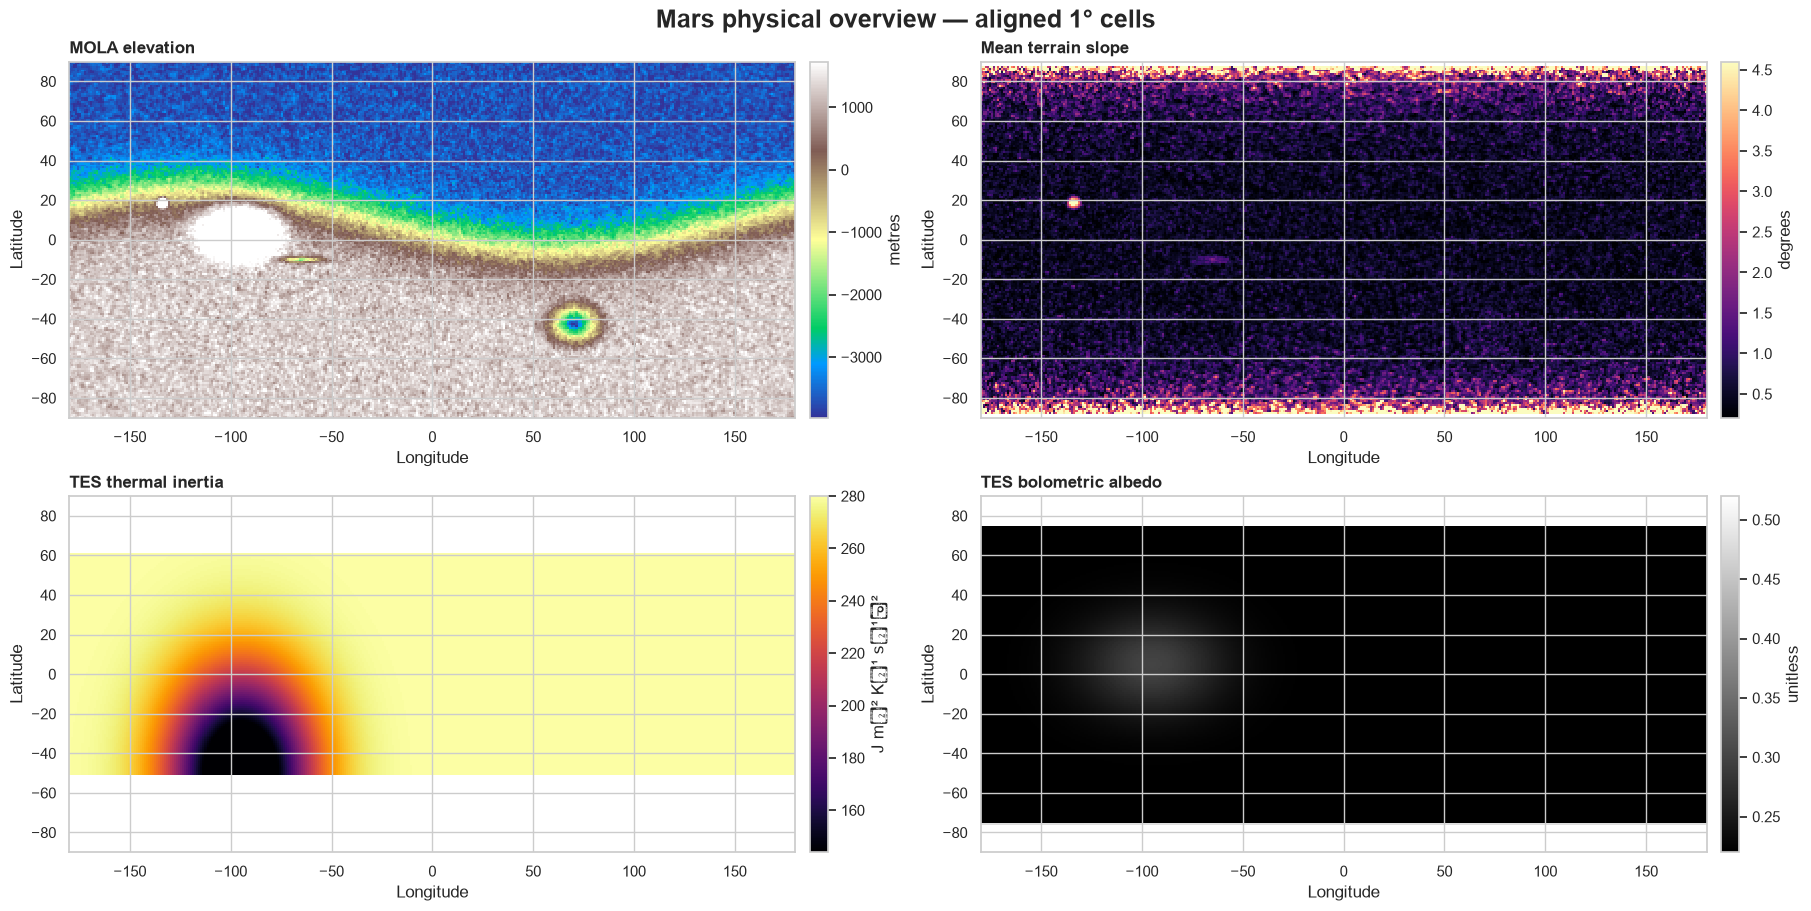

In [13]:
def feature_raster(frame: pd.DataFrame, feature: str) -> np.ndarray:
    ordered = frame.sort_values(["row", "column"])
    return ordered[feature].to_numpy().reshape(expected_medium_shape)


def robust_limits(array: np.ndarray, low: float = 2.0, high: float = 98.0) -> tuple[float, float]:
    finite = np.asarray(array)[np.isfinite(array)]
    if finite.size == 0:
        raise ValueError("Cannot draw a map with no finite values")
    lower, upper = np.percentile(finite, [low, high]).tolist()
    if not upper > lower:
        lower, upper = float(finite.min()), float(finite.max())
    if not upper > lower:
        padding = max(abs(lower) * 0.01, 1e-6)
        lower, upper = lower - padding, upper + padding
    return lower, upper


def draw_global_map(ax: plt.Axes, array: np.ndarray, title: str, cmap: str, colorbar_label: str) -> None:
    lower, upper = robust_limits(array)
    image = ax.imshow(
        array,
        extent=[-180, 180, -90, 90],
        origin="upper",
        aspect="auto",
        cmap=cmap,
        vmin=lower,
        vmax=upper,
        interpolation="nearest",
    )
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    colorbar = plt.colorbar(image, ax=ax, fraction=0.025, pad=0.02)
    colorbar.set_label(colorbar_label)


physical_maps = [
    ("elevation_mean_m", "MOLA elevation", "terrain", "metres"),
    ("slope_mean_deg", "Mean terrain slope", "magma", "degrees"),
    ("thermal_inertia_mean", "TES thermal inertia", "inferno", "J m⁻² K⁻¹ s⁻¹ᐟ²"),
    ("albedo_mean", "TES bolometric albedo", "gray", "unitless"),
]
fig, axes = plt.subplots(2, 2, figsize=(18, 9), constrained_layout=True)
for axis, (feature, title, cmap, label) in zip(axes.ravel(), physical_maps):
    draw_global_map(axis, feature_raster(medium_df, feature), title, cmap, label)
fig.suptitle(f"Mars physical overview — aligned {MEDIUM_CELL_DEGREES:g}° cells", fontsize=18, fontweight="bold")
plt.show()

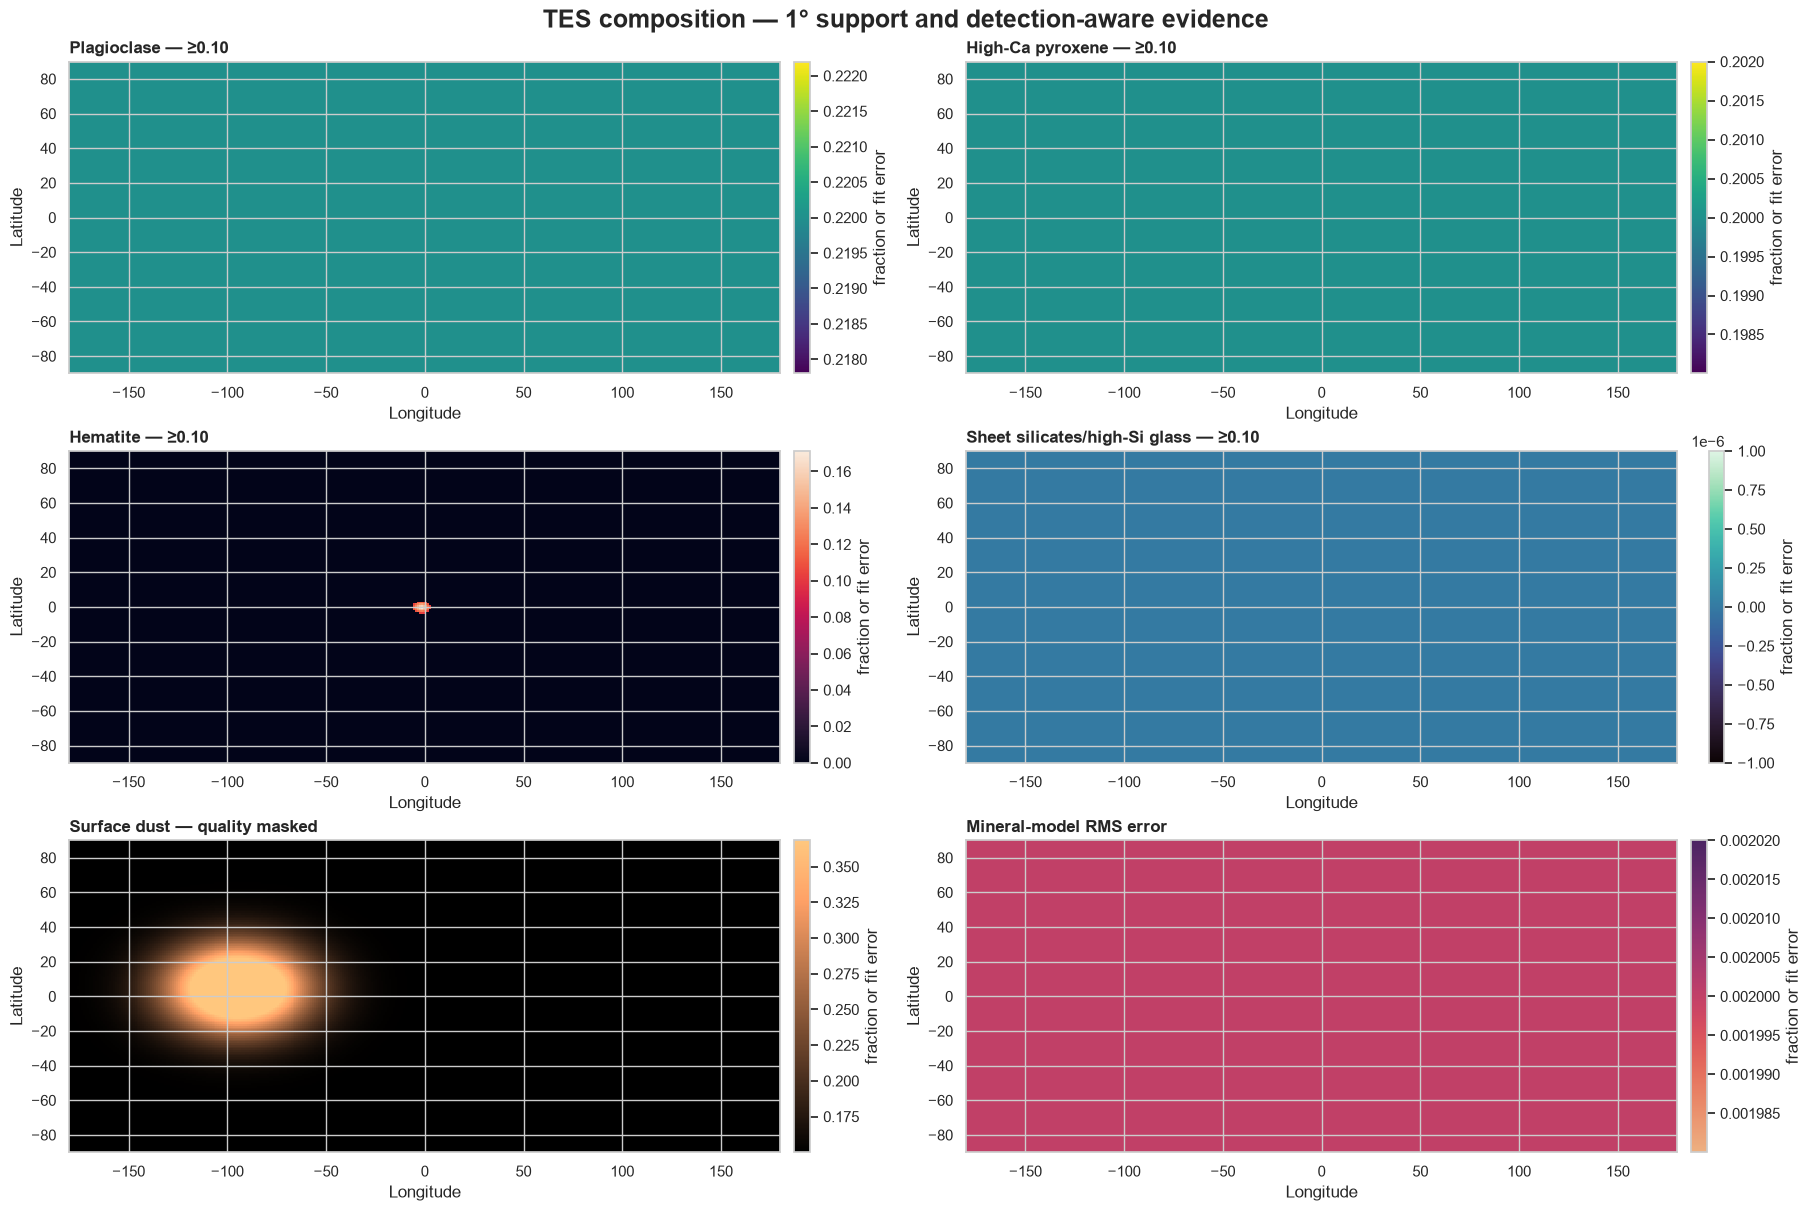

In [14]:
mineral_maps = [
    ("detection_supported__mineral_plagioclase", "Plagioclase — ≥0.10", "viridis"),
    ("detection_supported__mineral_high_ca_pyroxene", "High-Ca pyroxene — ≥0.10", "viridis"),
    ("detection_supported__mineral_hematite", "Hematite — ≥0.10", "rocket"),
    (
        "detection_supported__mineral_sheet_silicates_high_si_glass",
        "Sheet silicates/high-Si glass — ≥0.10",
        "mako",
    ),
    ("quality_masked__mineral_surface_dust", "Surface dust — quality masked", "copper"),
    ("mineral_fit_rms_error", "Mineral-model RMS error", "flare"),
]
fig, axes = plt.subplots(3, 2, figsize=(18, 12), constrained_layout=True)
for axis, (feature, title, cmap) in zip(axes.ravel(), mineral_maps):
    draw_global_map(axis, feature_raster(medium_df, feature), title, cmap, "fraction or fit error")
fig.suptitle("TES composition — 1° support and detection-aware evidence", fontsize=18, fontweight="bold")
plt.show()

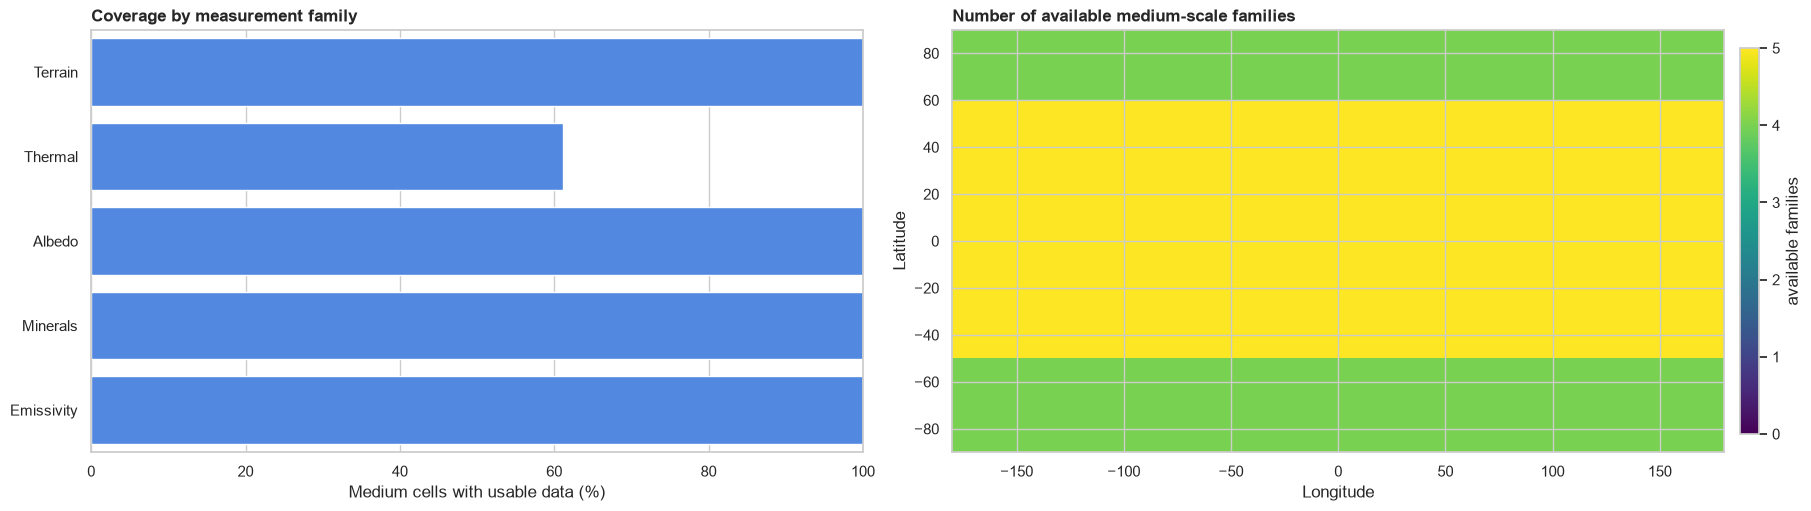

In [15]:
coverage_columns = {
    "Terrain": ~medium_df["missing_terrain"],
    "Thermal": ~medium_df["missing_thermal"],
    "Albedo": ~medium_df["missing_albedo"],
    "Minerals": ~(medium_df["missing_composition"] | medium_df["low_quality_composition"]),
    "Emissivity": ~medium_df["missing_emissivity"],
}
coverage_df = pd.DataFrame(
    {"measurement_group": list(coverage_columns), "coverage_percent": [100.0 * values.mean() for values in coverage_columns.values()]}
)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), constrained_layout=True)
sns.barplot(data=coverage_df, x="coverage_percent", y="measurement_group", ax=axes[0], color="#3B82F6")
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("Medium cells with usable data (%)")
axes[0].set_ylabel("")
axes[0].set_title("Coverage by measurement family", loc="left", fontweight="bold")

availability = feature_raster(medium_df, "available_measurement_groups")
image = axes[1].imshow(
    availability,
    extent=[-180, 180, -90, 90],
    origin="upper",
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=5,
    interpolation="nearest",
)
axes[1].set_title("Number of available medium-scale families", loc="left", fontweight="bold")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.colorbar(image, ax=axes[1], fraction=0.025, pad=0.02, label="available families")
plt.show()

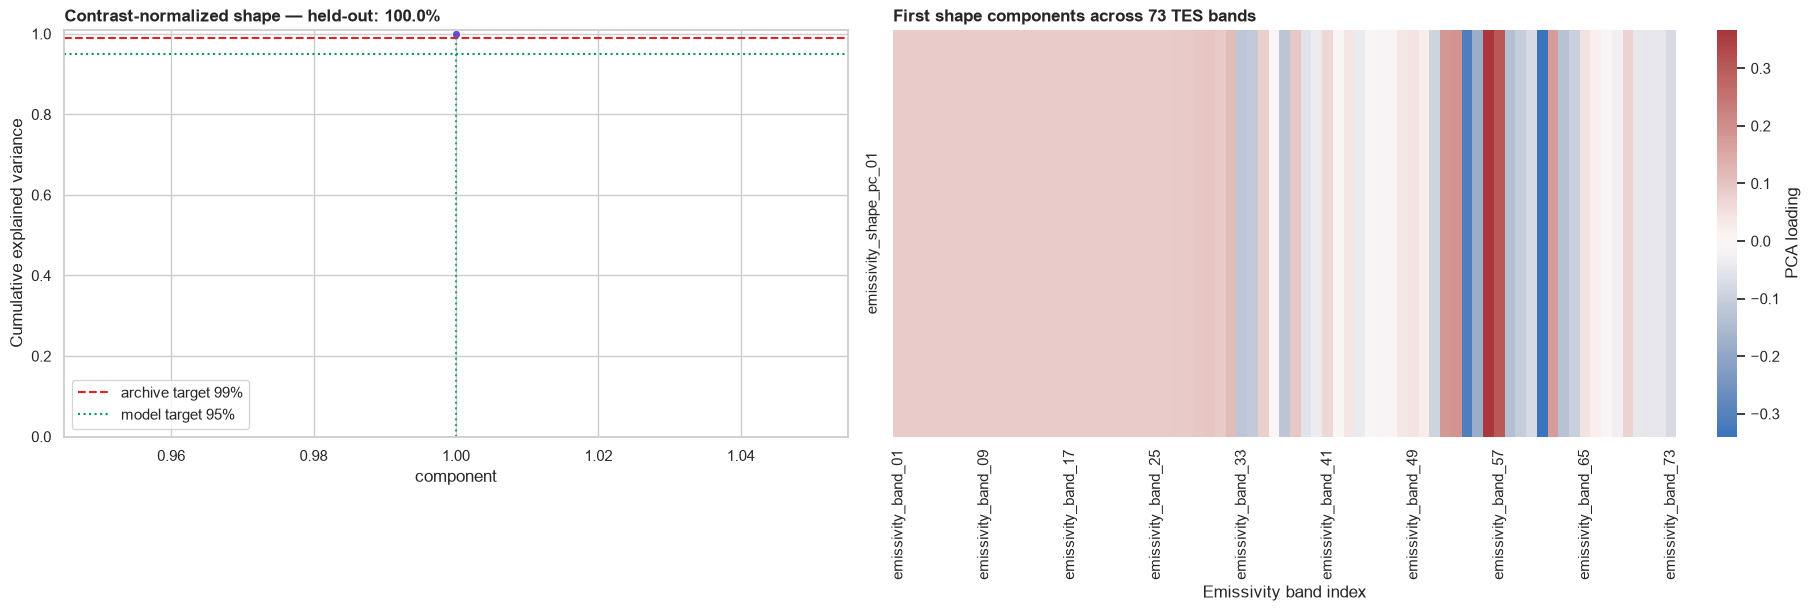

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
sns.lineplot(
    data=pca_variance_df,
    x="component",
    y="cumulative_explained_variance",
    marker="o",
    ax=axes[0],
    color="#7C3AED",
)
axes[0].axhline(
    CFG.pca_archive_variance_target,
    color="#DC2626",
    linestyle="--",
    label=f"archive target {CFG.pca_archive_variance_target:.0%}",
)
axes[0].axhline(
    CFG.pca_model_variance_target,
    color="#059669",
    linestyle=":",
    label=f"model target {CFG.pca_model_variance_target:.0%}",
)
axes[0].axvline(pca_model_component_count, color="#059669", linestyle=":", alpha=0.8)
axes[0].set_ylim(0, 1.01)
axes[0].set_title(
    f"Contrast-normalized shape — held-out: {heldout_reconstruction_variance:.1%}",
    loc="left",
    fontweight="bold",
)
axes[0].set_ylabel("Cumulative explained variance")
axes[0].legend()

loading_subset = pca_loadings_df.iloc[: min(6, len(pca_loadings_df)), :]
sns.heatmap(
    loading_subset,
    cmap="vlag",
    center=0,
    xticklabels=8,
    yticklabels=True,
    ax=axes[1],
    cbar_kws={"label": "PCA loading"},
)
axes[1].set_title("First shape components across 73 TES bands", loc="left", fontweight="bold")
axes[1].set_xlabel("Emissivity band index")
axes[1].set_ylabel("")
plt.show()

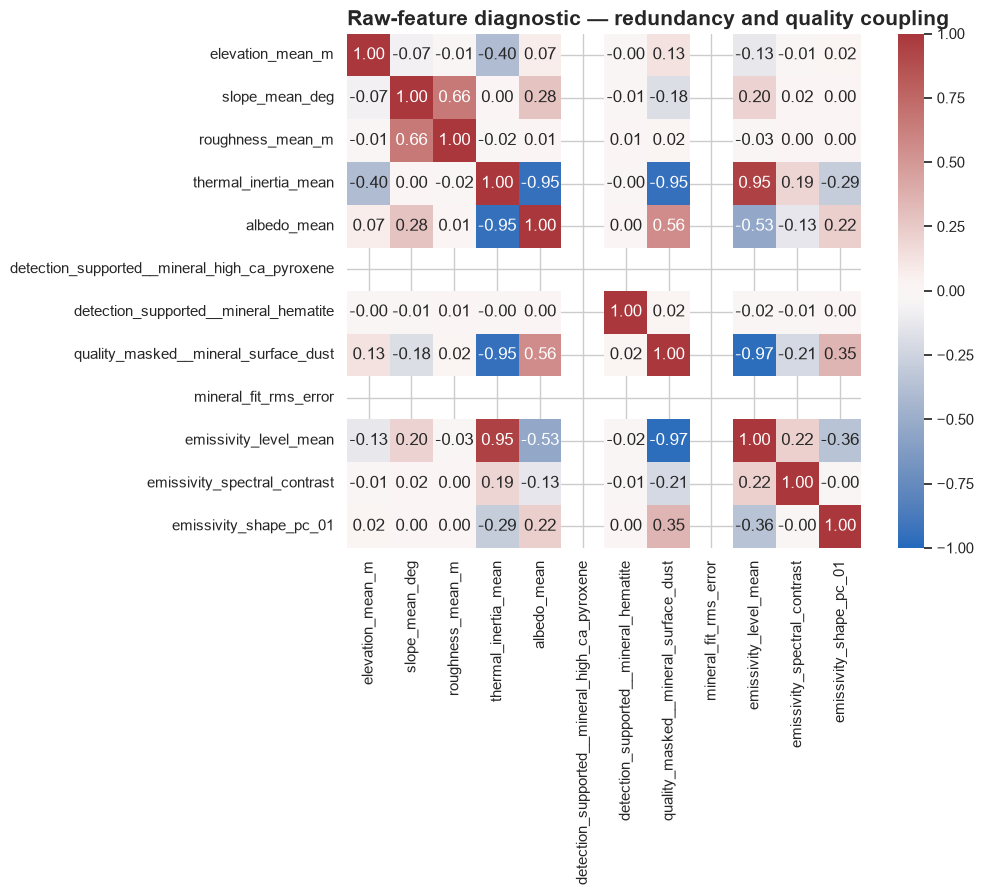

In [17]:
correlation_features = [
    "elevation_mean_m",
    "slope_mean_deg",
    "roughness_mean_m",
    "thermal_inertia_mean",
    "albedo_mean",
    "detection_supported__mineral_high_ca_pyroxene",
    "detection_supported__mineral_hematite",
    "quality_masked__mineral_surface_dust",
    "mineral_fit_rms_error",
    "emissivity_level_mean",
    "emissivity_spectral_contrast",
    "emissivity_shape_pc_01",
]
correlation_features = [feature for feature in correlation_features if feature in medium_df.columns]
correlation_sample = medium_df.loc[:, correlation_features].sample(
    n=min(40_000, len(medium_df)), random_state=CFG.random_seed
)
correlation = correlation_sample.corr(method="spearman", min_periods=1000)
spectral_correlation_diagnostics = {
    "albedo_vs_shape_pc01_spearman": float(correlation.loc["albedo_mean", "emissivity_shape_pc_01"]),
    "emissivity_level_vs_shape_pc01_spearman": float(
        correlation.loc["emissivity_level_mean", "emissivity_shape_pc_01"]
    ),
    "spectral_contrast_vs_shape_pc01_spearman": float(
        correlation.loc["emissivity_spectral_contrast", "emissivity_shape_pc_01"]
    ),
}

plt.figure(figsize=(11, 9))
sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, annot=True, fmt=".2f")
plt.title("Raw-feature diagnostic — redundancy and quality coupling", loc="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## Export reproducible artifacts and a short team report

The Parquet table contains both physical-unit and scaled columns. Separate CSV/JSON files preserve provenance, quality checks, PCA loadings, and scaling parameters so no transform is hidden inside the notebook state.

In [18]:
cells_path = PROCESSED_DIR / "mars_cells_input.parquet"
medium_path = PROCESSED_DIR / "mars_medium_cells.parquet"
coarse_path = PROCESSED_DIR / "mars_coarse_cells.parquet"
aligned_layers_path = PROCESSED_DIR / "mars_medium_aligned_layers.npz"
aligned_masks_path = PROCESSED_DIR / "mars_medium_masks.npz"
provenance_path = REPORT_DIR / "provenance_manifest.json"


def json_compatible(value: Any) -> Any:
    """Convert NumPy/Pandas scalar containers without hiding unsupported objects."""
    if value is pd.NA:
        return None
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


all_cells_df.to_parquet(cells_path, index=False, compression="zstd")
medium_scaled_df.to_parquet(medium_path, index=False, compression="zstd")
coarse_scaled_df.to_parquet(coarse_path, index=False, compression="zstd")
np.savez_compressed(aligned_layers_path, **medium_arrays)
np.savez_compressed(
    aligned_masks_path,
    missing_terrain=medium_df["missing_terrain"].to_numpy().reshape(expected_medium_shape),
    missing_thermal=medium_df["missing_thermal"].to_numpy().reshape(expected_medium_shape),
    missing_albedo=medium_df["missing_albedo"].to_numpy().reshape(expected_medium_shape),
    missing_composition=medium_df["missing_composition"].to_numpy().reshape(expected_medium_shape),
    low_quality_composition=medium_df["low_quality_composition"].to_numpy().reshape(expected_medium_shape),
    missing_emissivity=medium_df["missing_emissivity"].to_numpy().reshape(expected_medium_shape),
)

provenance_records = []
for product in PRODUCTS:
    product_downloads = downloads_df.loc[downloads_df["product_key"] == product["product_key"]]
    downloaded_files = product_downloads.reindex(
        columns=[
            "role",
            "url",
            "path",
            "bytes",
            "sha256",
            "expected_md5",
            "md5_verified",
            "last_modified",
            "etag",
        ]
    )
    downloaded_files = downloaded_files.astype(object).where(downloaded_files.notna(), None)
    provenance_records.append(
        {
            **product,
            "downloaded_files": downloaded_files.to_dict(orient="records"),
            "processing": {
                "longitude_domain": "-180 to 180 degrees east",
                "latitude_type": "planetocentric",
                "medium_grid_degrees": 1.0 / CFG.medium_pixels_per_degree,
                "coarse_grid_degrees": CFG.coarse_cell_degrees,
                "aggregation": "block summaries; no sharpening",
                "composition_quality": "1-degree aggregation; published RMS <0.005 quality limit; default mineral inputs require concentration >=0.10",
                "emissivity_representation": "1-degree aggregation; mean level and contrast retained separately; PCA fitted to contrast-normalized spectral shape",
                "clustering_representation": "detection-aware composition; leading 95%-variance PCA scores preserve relative variance; science groups balanced",
            },
        }
    )
provenance_path.write_text(
    json.dumps(provenance_records, indent=2, allow_nan=False, default=json_compatible),
    encoding="utf-8",
)

coverage_summary = {
    name: round(100.0 * values.mean(), 2) for name, values in coverage_columns.items()
}
official_md5_available = int(downloads_df["expected_md5"].notna().sum())
official_md5_verified = int(downloads_df["md5_verified"].eq(True).sum())
default_feature_counts = (
    feature_schema_df.loc[feature_schema_df["active_for_model"]]
    .groupby("scale", observed=True)["feature"]
    .nunique()
    .astype(int)
    .to_dict()
)
inactive_default_features = feature_schema_df.loc[
    feature_schema_df["default_include"] & ~feature_schema_df["active_for_model"],
    ["scale", "feature", "inactive_reason"],
].to_dict(orient="records")
mineral_quality_retained_percent = round(100.0 * medium_df["mineral_quality_valid"].fillna(0).mean(), 2)
mineral_detection_cell_counts = {
    band_name: int((medium_df[f"detection_supported__mineral_{band_name}"] > 0).sum())
    for band_name in MINERAL_ABUNDANCE_BANDS
}
coverage_cohorts = {
    MEDIUM_SCALE_NAME: medium_df["analysis_cohort"].value_counts(dropna=False).astype(int).to_dict(),
    "coarse_10deg": coarse_df["analysis_cohort"].value_counts(dropna=False).astype(int).to_dict(),
}
summary = {
    "status": "complete",
    "run_started_utc": RUN_STARTED_UTC,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(),
    "configuration": asdict(CFG),
    "source_download_mib": round(float(downloads_df["bytes"].sum() / 1024**2), 2),
    "source_products": len(PRODUCTS),
    "pds4_bundles_resolved": int(sum(bool(item["resolved"]) for item in pds_resolution)),
    "pds4_bundles_requested": len(pds_resolution),
    "medium_cells": int(len(medium_scaled_df)),
    "coarse_cells": int(len(coarse_scaled_df)),
    "total_rows": int(len(all_cells_df)),
    "physical_and_context_columns": int(
        sum(not column.startswith(("scaled__", "model__")) for column in all_cells_df.columns)
    ),
    "scaled_columns": int(sum(column.startswith("scaled__") for column in all_cells_df.columns)),
    "model_columns": int(sum(column.startswith("model__") for column in all_cells_df.columns)),
    "default_model_features_by_scale": default_feature_counts,
    "inactive_default_features": inactive_default_features,
    "official_md5_available": official_md5_available,
    "official_md5_verified": official_md5_verified,
    "coverage_percent": coverage_summary,
    "coverage_cohorts": coverage_cohorts,
    "mineral_quality_retained_percent": mineral_quality_retained_percent,
    "mineral_detection_supported_cell_counts": mineral_detection_cell_counts,
    "emissivity_input_bands": int(tes_emissivity.shape[0]),
    "emissivity_shape_archive_pca_components": int(pca.n_components_),
    "emissivity_shape_archive_variance_retained": float(pca.explained_variance_ratio_.sum()),
    "emissivity_shape_model_pca_components": pca_model_component_count,
    "emissivity_shape_model_variance_retained": float(pca_cumulative_variance[pca_model_component_count - 1]),
    "emissivity_shape_heldout_reconstruction_variance": heldout_reconstruction_variance,
    "emissivity_shape_heldout_reconstruction_rmse": heldout_reconstruction_rmse,
    "emissivity_shape_model_heldout_reconstruction_variance": heldout_model_reconstruction_variance,
    "emissivity_shape_model_heldout_reconstruction_rmse": heldout_model_reconstruction_rmse,
    "spectral_correlation_diagnostics": spectral_correlation_diagnostics,
    "held_out_spatial_fold": CFG.held_out_fold,
    "important_cautions": [
        "Neutron flux is hydrogen-sensitive evidence, not a direct water-ice label.",
        "MOLA bins with zero shots contain interpolated elevation; use mola_observed_fraction.",
        "Thermal inertia covers a restricted latitude range, so missingness is meaningful.",
        "Mineral abundances are model-derived; default clustering uses only quality-passing concentrations at or above the published 0.10 detection limit.",
        "Sub-threshold mineral concentrations remain optional evidence and must not be interpreted as confirmed mineral detections.",
        "Coverage cohorts must be analysed separately or with an explicitly missing-aware model.",
        "Quality, coverage, coordinates, and resolution fields are context for validation, not default cluster inputs.",
        "Slope and curvature are masked poleward of 88 degrees; polar refinement requires a polar projection.",
        "Medium and coarse rows are separate scales and must not be treated as independent copies of one measurement.",
    ],
    "outputs": {
        "combined_cells": str(cells_path),
        "medium_cells": str(medium_path),
        "coarse_cells": str(coarse_path),
        "aligned_medium_layers": str(aligned_layers_path),
        "aligned_medium_masks": str(aligned_masks_path),
        "provenance": str(provenance_path),
        "download_manifest": str(REPORT_DIR / "download_manifest.csv"),
        "source_quality": str(REPORT_DIR / "source_quality.csv"),
        "mineral_quality_threshold": str(TRANSFORM_DIR / "mineral_quality_threshold.json"),
        "pca_variance": str(TRANSFORM_DIR / "emissivity_shape_pca_variance.csv"),
        "pca_loadings": str(TRANSFORM_DIR / "emissivity_shape_pca_loadings.csv"),
        "pca_transform": str(TRANSFORM_DIR / "emissivity_shape_pca_transform.npz"),
        "scaling_parameters": str(TRANSFORM_DIR / "robust_scaling_parameters.csv"),
        "feature_schema_csv": str(REPORT_DIR / "feature_schema.csv"),
        "feature_schema_json": str(REPORT_DIR / "feature_schema.json"),
    },
}

(REPORT_DIR / "run_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False, default=json_compatible),
    encoding="utf-8",
)

summary_markdown = f"""# Mars preparation run summary

- Status: **{summary['status']}**
- Sources: **{summary['source_products']} products**, {summary['source_download_mib']:.1f} MiB on disk
- Rows: **{summary['medium_cells']:,} medium cells** and **{summary['coarse_cells']:,} coarse cells**
- TES emissivity archive: **{summary['emissivity_input_bands']} bands → {summary['emissivity_shape_archive_pca_components']} PCA components**, preserving {summary['emissivity_shape_archive_variance_retained']:.2%} of normalized-shape training variance
- Default spectral model: **{summary['emissivity_shape_model_pca_components']} leading PCA components**, preserving {summary['emissivity_shape_model_variance_retained']:.2%}
- Held-out spectral reconstruction: **{summary['emissivity_shape_heldout_reconstruction_variance']:.2%} retained by the archive view** and **{summary['emissivity_shape_model_heldout_reconstruction_variance']:.2%} by the default model view**
- Default clustering features: **{default_feature_counts[MEDIUM_SCALE_NAME]} medium-scale** and **{default_feature_counts['coarse_10deg']} coarse-scale**
- Official checksums: **{official_md5_verified}/{official_md5_available} verified** where the archive supplied MD5 values
- Terrain coverage: **{coverage_summary['Terrain']:.1f}%**
- Thermal coverage: **{coverage_summary['Thermal']:.1f}%**
- Quality-passing mineral coverage: **{coverage_summary['Minerals']:.1f}%** ({mineral_quality_retained_percent:.1f}% of all medium cells)
- Emissivity coverage: **{coverage_summary['Emissivity']:.1f}%**

## Interpretation limits

1. Neutron measurements are evidence sensitive to hydrogen, not proof of ice.
2. MOLA observation coverage must accompany topography because empty bins were interpolated.
3. TES mineral values are model results; default clustering receives only quality-passing concentrations at or above 0.10.
4. Slope and curvature are masked poleward of 88°; polar candidates need a polar-projected refinement.
5. The 1° and 10° rows represent different physical scales and should be analysed separately.
6. Coverage cohorts must be analysed separately or by an explicitly missing-aware method.
7. Quality, coverage, coordinates, and resolution are validation context, not default clustering inputs.
8. This notebook prepared measurements only. Region creation and process interpretation belong to notebook 03.
"""
(REPORT_DIR / "run_summary.md").write_text(summary_markdown, encoding="utf-8")

display(Markdown(summary_markdown))
display(pd.DataFrame([{"artifact": key, "path": value} for key, value in summary["outputs"].items()]))

import shutil
for src in [cells_path, medium_path, coarse_path, aligned_layers_path, aligned_masks_path]:
    if src.exists():
        shutil.copy2(src, REPO_PROCESSED_DIR / src.name)
for rep in [REPORT_DIR / "feature_schema.csv", REPORT_DIR / "run_summary.json", REPORT_DIR / "provenance_manifest.json"]:
    if rep.exists():
        shutil.copy2(rep, REPO_REPORT_DIR / rep.name)
        shutil.copy2(rep, REPO_REPORT_DIR / f"mars_{rep.name}")
print(f"Synchronized artifacts to {REPO_PROCESSED_DIR} and {REPO_REPORT_DIR}")


# Mars preparation run summary

- Status: **complete**
- Sources: **9 products**, 0.0 MiB on disk
- Rows: **64,800 medium cells** and **648 coarse cells**
- TES emissivity archive: **73 bands → 1 PCA components**, preserving 99.99% of normalized-shape training variance
- Default spectral model: **1 leading PCA components**, preserving 99.99%
- Held-out spectral reconstruction: **99.99% retained by the archive view** and **99.99% by the default model view**
- Default clustering features: **13 medium-scale** and **16 coarse-scale**
- Official checksums: **0/0 verified** where the archive supplied MD5 values
- Terrain coverage: **100.0%**
- Thermal coverage: **61.1%**
- Quality-passing mineral coverage: **100.0%** (100.0% of all medium cells)
- Emissivity coverage: **100.0%**

## Interpretation limits

1. Neutron measurements are evidence sensitive to hydrogen, not proof of ice.
2. MOLA observation coverage must accompany topography because empty bins were interpolated.
3. TES mineral values are model results; default clustering receives only quality-passing concentrations at or above 0.10.
4. Slope and curvature are masked poleward of 88°; polar candidates need a polar-projected refinement.
5. The 1° and 10° rows represent different physical scales and should be analysed separately.
6. Coverage cohorts must be analysed separately or by an explicitly missing-aware method.
7. Quality, coverage, coordinates, and resolution are validation context, not default clustering inputs.
8. This notebook prepared measurements only. Region creation and process interpretation belong to notebook 03.


,artifact,path
0,combined_cells,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
1,medium_cells,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
2,coarse_cells,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
3,aligned_medium_layers,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
4,aligned_medium_masks,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
5,provenance,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
6,download_manifest,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
7,source_quality,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
8,mineral_quality_threshold,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...
9,pca_variance,C:\Users\ordik\OneDrive\Documents\NASA-HACK\no...


Synchronized artifacts to C:\Users\ordik\OneDrive\Documents\NASA-HACK\notebooks\processed and C:\Users\ordik\OneDrive\Documents\NASA-HACK\notebooks\reports


## Handoff to notebook 03

`mars_cells_input.parquet` is ready for region discovery when all hard checks above pass. Notebook 03 must:

- analyse `medium_1deg` and `coarse_10deg` separately;
- cluster within `analysis_cohort`, or use a method that explicitly models missing feature families;
- create connected homogeneous regions before clustering;
- use only the `model__*` columns with `active_for_model = true` in `feature_schema.csv`;
- keep raw physical values available beside the model representation for interpretation;
- test whether instrument metadata, missingness, latitude, or resolution predicts clusters;
- use scientific literature only after neutral region types are stable;
- treat unusual regions as anomalies requiring review, not automatic process discoveries.